SPDX-License-Identifier: Apache-2.0 — See LICENSE for full terms
> Created by Patrick Woo, 2025  
> This file is part of the FPS-R (Frame-Persistent Stateless Randomisation) project.  
> https://github.com/patwooky/fpsr

# **FPS-R**

## **Frame-Persistent Stateless Randomisation**
**FPS-R** stands for **Frame-Persistent Stateless Randomisation**. It is a philosophy and framework behind a collection of lightweight algorithmic pattern for simulating persistent yet stateless randomness across a continuous timeline—ideal for procedural motion, glitch aesthetics, synthesised organic behaviour, and analogue artefact emulation.

### Algorithms
This notebook will provide the Python code for the following FPS-R Algorithms:
- **Stacked Modulo (SM)**
- **Toggled Modulo (TM)**
- **Quantised Switching (QS)**
- **Bitwise Decode (BD)**

In [155]:
# Created in Python 3.13.5
# import libraries
import os
import sys
import json
import time
import math
import random
import threading
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Add inline plotting for matplotlib
%matplotlib inline

## FPS-R Helper Functions
These functions are support the FPS-R `fpsr_xx_base()` and `fpsr_xx_get_details()` functions

#### Helper Functions for Deterministic Operations
These helper functions ensure deterministic behavior across platforms and match the C reference implementation.

In [156]:
# Bit-width used for chunked bit operations. Must remain 64 for deterministic compatibility.
_CHUNK_BITS = 64

# 64-bit mask for emulating uint64_t wraparound exactly like C.
_UINT64_MASK = (1 << _CHUNK_BITS) - 1

def _to_uint64(x: int) -> int:
    """Cast any Python int to an emulated uint64_t by masking to 64 bits."""
    return x & _UINT64_MASK

def i64_floor_mod(a: int, m: int) -> int:
    """Return a modulo m using floor semantics, identical to Python's % for m>0."""
    return a % m

def i64_align_down(a: int, m: int) -> int:
    """Align a down to a multiple of m using floor-mod semantics."""
    return a - i64_floor_mod(a, m)

def _splitmix64(x: int) -> int:
    """SplitMix64: portable 64-bit mixer with well-defined unsigned wraparound."""
    x = _to_uint64(x + 0x9E3779B97F4A7C15)
    x = _to_uint64((x ^ (x >> 30)) * 0xBF58476D1CE4E5B9)
    x = _to_uint64((x ^ (x >> 27)) * 0x94D049BB133111EB)
    x = _to_uint64(x ^ (x >> 31))
    return x

def portable_rand_u64(seed: int) -> float:
    """Portable, deterministic PRNG that returns a double in [0,1)."""
    r = _splitmix64(_to_uint64(seed))
    return float((r >> 11)) * (1.0 / 9007199254740992.0)  # 2^53

def portable_rand(seed):
    """
    A simple, portable pseudo-random number generator.
    Generates a deterministic float between 0.0 and 1.0 from an integer-like seed.
    This wrapper forwards to a 64-bit deterministic PRNG that mirrors the C code.

    Args:
        seed (int|float): An integer-like seed. Floats are floored for determinism.

    Returns:
        float: A pseudo-random float between 0.0 and 1.0.
    """
    if isinstance(seed, float):
        seed = math.floor(seed)
    else:
        seed = int(seed)
    return portable_rand_u64(seed)

def _circular_left_shift(value: int, shift: int) -> int:
    """Performs a _CHUNK_BITS-wide circular left shift (rotate left)."""
    shift %= _CHUNK_BITS
    if shift == 0: return _to_uint64(value)
    return _to_uint64((value << shift) | (value >> (_CHUNK_BITS - shift)))

def _circular_right_shift(value: int, shift: int) -> int:
    """Performs a _CHUNK_BITS-wide circular right shift (rotate right)."""
    shift %= _CHUNK_BITS
    if shift == 0: return _to_uint64(value)
    return _to_uint64((value >> shift) | (value << (_CHUNK_BITS - shift)))

#### Wavetable Type & Sampler Implementation
Lightweight power-of-2 cyclical wavetable sampler with linear interpolation and unipolar mapping [0.0, 1.0].

In [157]:
# -----------------------------------------------------------------------------
# Wavetable Type & Sampler
# -----------------------------------------------------------------------------

class FPSR_Wavetable:
    """
    Lightweight container for power-of-2 cyclical wavetables.
    Pass None to functions to use the default 1024-entry unipolar sine table.
    """
    def __init__(self, samples: list):
        self.samples = samples
        self.size = len(samples)

_TWO_PI = 6.28318530718

# Python Sine Wavetable (1024-point normalized unipolar sine [0.0, 1.0])
_fpsr_sine_lut_1024 = [\
    0.5000000000000000, 0.5030679423245772, 0.5061357691428600, 0.5092033649529024, 0.5122706142614561,
    0.5153374015883183, 0.5184036114706794, 0.5214691284674704, 0.5245338371637090, 0.5275976221748450,
    0.5306603681511043, 0.5337219597818320, 0.5367822817998337, 0.5398412189857150, 0.5428986561722200,
    0.5459544782485664, 0.5490085701647803, 0.5520608169360273, 0.5551111036469415, 0.5581593154559523,
    0.5612053375996081, 0.5642490553968966, 0.5672903542535631, 0.5703291196664246, 0.5733652372276808,
    0.5763985926292217, 0.5794290716669307, 0.5824565602449849, 0.5854809443801506, 0.5885021102060743,
    0.5915199439775705, 0.5945343320749031, 0.5975451610080641, 0.6005523174210460, 0.6035556880961093,
    0.6065551599580457, 0.6095506200784349, 0.6125419556798964, 0.6155290541403355, 0.6185118029971836,
    0.6214900899516319, 0.6244638028728601, 0.6274328298022573, 0.6303970589576378, 0.6333563787374492,
    0.6363106777249745, 0.6392598446925265, 0.6422037686056359, 0.6451423386272311, 0.6480754441218119,
    0.6510029746596140, 0.6539248200207675, 0.6568408701994457, 0.6597510154080078, 0.6626551460811314,
    0.6655531528799382, 0.6684449266961100, 0.6713303586559972, 0.6742093401247173, 0.6770817627102452,
    0.6799475182674941, 0.6828064989023870, 0.6856585969759188, 0.6885037051082091, 0.6913417161825449,
    0.6941725233494132, 0.6969960200305241, 0.6998120999228234, 0.7026206570024949, 0.7054215855289520,
    0.7082147800488185, 0.7110001353998998, 0.7137775467151410, 0.7165469094265760, 0.7193081192692639,
    0.7220610722852145, 0.7248056648273032, 0.7275417935631719, 0.7302693554791200, 0.7329882478839831,
    0.7356983684129988, 0.7383996150316611, 0.7410918860395613, 0.7437750800742180, 0.7464490961148920,
    0.7491138334863909, 0.7517691918628588, 0.7544150712715535, 0.7570513720966108, 0.7596779950827948,
    0.7622948413392345, 0.7649018123431472, 0.7674988099435486, 0.7700857363649465, 0.7726624942110232,
    0.7752289864683024, 0.7777851165098011, 0.7803307880986681, 0.7828659053918066, 0.7853903729434837,
    0.7879040957089227, 0.7904069790478823, 0.7928989287282194, 0.7953798509294371, 0.7978496522462166,
    0.8003082396919345, 0.8027555207021628, 0.8051914031381547, 0.8076157952903134, 0.8100286058816446,
    0.8124297440711932, 0.8148191194574634, 0.8171966420818227, 0.8195622224318879, 0.8219157714448957,
    0.8242572005110562, 0.8265864214768883, 0.8289033466485394, 0.8312078887950859, 0.8334999611518188,
    0.8357794774235092, 0.8380463517876580, 0.8403004988977265, 0.8425418338863502, 0.8447702723685334,
    0.8469857304448269, 0.8491881247044863, 0.8513773722286126, 0.8535533905932737, 0.8557160978726082,
    0.8578654126419093, 0.8600012539806908, 0.8621235414757334, 0.8642321952241125, 0.8663271358362064,
    0.8684082844386849, 0.8704755626774796, 0.8725288927207330, 0.8745681972617296, 0.8765933995218063,
    0.8786044232532423, 0.8806011927421309, 0.8825836328112295, 0.8845516688227898, 0.8865052266813684,
    0.8884442328366162, 0.8903686142860472, 0.8922782985777876, 0.8941732138133032, 0.8960532886501061,
    0.8979184523044417, 0.8997686345539525, 0.9016037657403224, 0.9034237767718996, 0.9052285991262974,
    0.9070181648529742, 0.9087924065757919, 0.9105512574955523, 0.9122946513925126, 0.9140225226288778,
    0.9157348061512727, 0.9174314374931900, 0.9191123527774190, 0.9207774887184492, 0.9224267826248536,
    0.9240601724016486, 0.9256775965526326, 0.9272789941827002, 0.9288643050001361, 0.9304334693188836,
    0.9319864280607933, 0.9335231227578463, 0.9350434955543556, 0.9365474892091450, 0.9380350470977032,
    0.9395061132143168, 0.9409606321741775, 0.9423985492154690, 0.9438198102014270, 0.9452243616223790,
    0.9466121505977576, 0.9479831248780926, 0.9493372328469769, 0.9506744235230110, 0.9519946465617217,
    0.9532978522574577, 0.9545839915452612, 0.9558530160027150, 0.9571048778517653, 0.9583395299605213,
    0.9595569258450289, 0.9607570196710209, 0.9619397662556434, 0.9631051210691557, 0.9642530402366079,
    0.9653834805394919, 0.9664963994173694, 0.9675917549694737, 0.9686695059562875, 0.9697296118010950,
    0.9707720325915103, 0.9717967290809801, 0.9728036626902606, 0.9737927955088705, 0.9747640902965183,
    0.9757175104845042, 0.9766530201770969, 0.9775705841528853, 0.9784701678661045, 0.9793517374479358,
    0.9802152597077829, 0.9810607021345208, 0.9818880328977200, 0.9826972208488447, 0.9834882355224260,
    0.9842610471372086, 0.9850156265972720, 0.9857519454931258, 0.9864699761027800, 0.9871696913927879,
    0.9878510650192642, 0.9885140713288771, 0.9891586853598138, 0.9897848828427203, 0.9903926402016152,
    0.9909819345547777, 0.9915527437156082, 0.9921050461934645, 0.9926388211944706, 0.9931540486222994,
    0.9936507090789293, 0.9941287838653747, 0.9945882549823906, 0.9950291051311486, 0.9954513177138899,
    0.9958548768345498, 0.9962397672993550, 0.9966059746173972, 0.9969534850011781, 0.9972822853671277,
    0.9975923633360984, 0.9978837072338299, 0.9981563060913889, 0.9984101496455828, 0.9986452283393451,
    0.9988615333220958, 0.9990590564500745, 0.9992377902866474, 0.9993977281025862, 0.9995388638763227,
    0.9996611922941747, 0.9997647087505466, 0.9998494093481021, 0.9999152908979116, 0.9999623509195723,
    0.9999905876413006, 1.0000000000000000, 0.9999905876413006, 0.9999623509195723, 0.9999152908979116,
    0.9998494093481021, 0.9997647087505466, 0.9996611922941747, 0.9995388638763227, 0.9993977281025862,
    0.9992377902866474, 0.9990590564500745, 0.9988615333220958, 0.9986452283393451, 0.9984101496455828,
    0.9981563060913889, 0.9978837072338299, 0.9975923633360985, 0.9972822853671277, 0.9969534850011781,
    0.9966059746173972, 0.9962397672993550, 0.9958548768345498, 0.9954513177138899, 0.9950291051311486,
    0.9945882549823906, 0.9941287838653747, 0.9936507090789293, 0.9931540486222994, 0.9926388211944706,
    0.9921050461934645, 0.9915527437156082, 0.9909819345547777, 0.9903926402016152, 0.9897848828427203,
    0.9891586853598138, 0.9885140713288771, 0.9878510650192642, 0.9871696913927879, 0.9864699761027801,
    0.9857519454931258, 0.9850156265972720, 0.9842610471372086, 0.9834882355224260, 0.9826972208488447,
    0.9818880328977200, 0.9810607021345208, 0.9802152597077829, 0.9793517374479358, 0.9784701678661045,
    0.9775705841528853, 0.9766530201770969, 0.9757175104845042, 0.9747640902965183, 0.9737927955088705,
    0.9728036626902608, 0.9717967290809801, 0.9707720325915103, 0.9697296118010950, 0.9686695059562875,
    0.9675917549694738, 0.9664963994173694, 0.9653834805394919, 0.9642530402366079, 0.9631051210691557,
    0.9619397662556434, 0.9607570196710210, 0.9595569258450289, 0.9583395299605213, 0.9571048778517653,
    0.9558530160027150, 0.9545839915452612, 0.9532978522574577, 0.9519946465617217, 0.9506744235230110,
    0.9493372328469769, 0.9479831248780926, 0.9466121505977576, 0.9452243616223790, 0.9438198102014270,
    0.9423985492154690, 0.9409606321741775, 0.9395061132143168, 0.9380350470977032, 0.9365474892091451,
    0.9350434955543557, 0.9335231227578464, 0.9319864280607935, 0.9304334693188836, 0.9288643050001361,
    0.9272789941827002, 0.9256775965526326, 0.9240601724016486, 0.9224267826248536, 0.9207774887184492,
    0.9191123527774191, 0.9174314374931900, 0.9157348061512727, 0.9140225226288778, 0.9122946513925125,
    0.9105512574955523, 0.9087924065757919, 0.9070181648529743, 0.9052285991262974, 0.9034237767718998,
    0.9016037657403224, 0.8997686345539526, 0.8979184523044418, 0.8960532886501061, 0.8941732138133032,
    0.8922782985777875, 0.8903686142860473, 0.8884442328366162, 0.8865052266813686, 0.8845516688227898,
    0.8825836328112295, 0.8806011927421309, 0.8786044232532424, 0.8765933995218063, 0.8745681972617296,
    0.8725288927207331, 0.8704755626774795, 0.8684082844386850, 0.8663271358362064, 0.8642321952241127,
    0.8621235414757334, 0.8600012539806909, 0.8578654126419094, 0.8557160978726084, 0.8535533905932737,
    0.8513773722286126, 0.8491881247044865, 0.8469857304448269, 0.8447702723685335, 0.8425418338863502,
    0.8403004988977266, 0.8380463517876580, 0.8357794774235092, 0.8334999611518188, 0.8312078887950860,
    0.8289033466485394, 0.8265864214768883, 0.8242572005110562, 0.8219157714448957, 0.8195622224318879,
    0.8171966420818227, 0.8148191194574637, 0.8124297440711932, 0.8100286058816447, 0.8076157952903135,
    0.8051914031381548, 0.8027555207021628, 0.8003082396919344, 0.7978496522462167, 0.7953798509294371,
    0.7928989287282195, 0.7904069790478823, 0.7879040957089227, 0.7853903729434837, 0.7828659053918068,
    0.7803307880986681, 0.7777851165098011, 0.7752289864683024, 0.7726624942110232, 0.7700857363649465,
    0.7674988099435486, 0.7649018123431475, 0.7622948413392345, 0.7596779950827949, 0.7570513720966109,
    0.7544150712715536, 0.7517691918628588, 0.7491138334863909, 0.7464490961148921, 0.7437750800742180,
    0.7410918860395614, 0.7383996150316611, 0.7356983684129990, 0.7329882478839831, 0.7302693554791201,
    0.7275417935631719, 0.7248056648273035, 0.7220610722852147, 0.7193081192692637, 0.7165469094265761,
    0.7137775467151410, 0.7110001353998999, 0.7082147800488185, 0.7054215855289521, 0.7026206570024950,
    0.6998120999228236, 0.6969960200305241, 0.6941725233494133, 0.6913417161825449, 0.6885037051082090,
    0.6856585969759188, 0.6828064989023869, 0.6799475182674941, 0.6770817627102452, 0.6742093401247173,
    0.6713303586559972, 0.6684449266961101, 0.6655531528799382, 0.6626551460811316, 0.6597510154080080,
    0.6568408701994457, 0.6539248200207675, 0.6510029746596140, 0.6480754441218119, 0.6451423386272312,
    0.6422037686056361, 0.6392598446925266, 0.6363106777249746, 0.6333563787374492, 0.6303970589576380,
    0.6274328298022573, 0.6244638028728601, 0.6214900899516320, 0.6185118029971836, 0.6155290541403357,
    0.6125419556798964, 0.6095506200784351, 0.6065551599580457, 0.6035556880961094, 0.6005523174210460,
    0.5975451610080643, 0.5945343320749031, 0.5915199439775705, 0.5885021102060745, 0.5854809443801506,
    0.5824565602449850, 0.5794290716669307, 0.5763985926292219, 0.5733652372276810, 0.5703291196664247,
    0.5672903542535631, 0.5642490553968965, 0.5612053375996082, 0.5581593154559523, 0.5551111036469416,
    0.5520608169360273, 0.5490085701647804, 0.5459544782485664, 0.5428986561722201, 0.5398412189857151,
    0.5367822817998339, 0.5337219597818321, 0.5306603681511043, 0.5275976221748451, 0.5245338371637089,
    0.5214691284674705, 0.5184036114706794, 0.5153374015883184, 0.5122706142614561, 0.5092033649529025,
    0.5061357691428600, 0.5030679423245774, 0.5000000000000001, 0.4969320576754227, 0.4938642308571401,
    0.4907966350470976, 0.4877293857385440, 0.4846625984116817, 0.4815963885293207, 0.4785308715325296,
    0.4754661628362911, 0.4724023778251551, 0.4693396318488959, 0.4662780402181680, 0.4632177182001663,
    0.4601587810142850, 0.4571013438277801, 0.4540455217514338, 0.4509914298352197, 0.4479391830639728,
    0.4448888963530585, 0.4418406845440478, 0.4387946624003919, 0.4357509446031036, 0.4327096457464370,
    0.4296708803335754, 0.4266347627723192, 0.4236014073707783, 0.4205709283330694, 0.4175434397550151,
    0.4145190556198495, 0.4114978897939257, 0.4084800560224296, 0.4054656679250970, 0.4024548389919358,
    0.3994476825789541, 0.3964443119038907, 0.3934448400419544, 0.3904493799215651, 0.3874580443201037,
    0.3844709458596645, 0.3814881970028166, 0.3785099100483681, 0.3755361971271400, 0.3725671701977428,
    0.3696029410423622, 0.3666436212625509, 0.3636893222750255, 0.3607401553074736, 0.3577962313943641,
    0.3548576613727690, 0.3519245558781881, 0.3489970253403861, 0.3460751799792326, 0.3431591298005544,
    0.3402489845919922, 0.3373448539188685, 0.3344468471200619, 0.3315550733038899, 0.3286696413440029,
    0.3257906598752827, 0.3229182372897549, 0.3200524817325059, 0.3171935010976132, 0.3143414030240813,
    0.3114962948917910, 0.3086582838174552, 0.3058274766505868, 0.3030039799694760, 0.3001879000771766,
    0.2973793429975051, 0.2945784144710480, 0.2917852199511816, 0.2889998646001002, 0.2862224532848591,
    0.2834530905734240, 0.2806918807307364, 0.2779389277147855, 0.2751943351726966, 0.2724582064368282,
    0.2697306445208800, 0.2670117521160170, 0.2643016315870012, 0.2616003849683390, 0.2589081139604387,
    0.2562249199257822, 0.2535509038851080, 0.2508861665136092, 0.2482308081371413, 0.2455849287284464,
    0.2429486279033892, 0.2403220049172052, 0.2377051586607656, 0.2350981876568527, 0.2325011900564515,
    0.2299142636350536, 0.2273375057889769, 0.2247710135316976, 0.2222148834901990, 0.2196692119013320,
    0.2171340946081934, 0.2146096270565164, 0.2120959042910773, 0.2095930209521178, 0.2071010712717806,
    0.2046201490705630, 0.2021503477537834, 0.1996917603080657, 0.1972444792978373, 0.1948085968618453,
    0.1923842047096866, 0.1899713941183554, 0.1875702559288069, 0.1851808805425365, 0.1828033579181774,
    0.1804377775681121, 0.1780842285551044, 0.1757427994889438, 0.1734135785231117, 0.1710966533514607,
    0.1687921112049141, 0.1665000388481813, 0.1642205225764908, 0.1619536482123421, 0.1596995011022735,
    0.1574581661136499, 0.1552297276314666, 0.1530142695551731, 0.1508118752955136, 0.1486226277713875,
    0.1464466094067263, 0.1442839021273918, 0.1421345873580908, 0.1399987460193092, 0.1378764585242666,
    0.1357678047758874, 0.1336728641637936, 0.1315917155613151, 0.1295244373225206, 0.1274711072792671,
    0.1254318027382705, 0.1234066004781938, 0.1213955767467579, 0.1193988072578690, 0.1174163671887705,
    0.1154483311772103, 0.1134947733186317, 0.1115557671633837, 0.1096313857139528, 0.1077217014222125,
    0.1058267861866971, 0.1039467113498938, 0.1020815476955583, 0.1002313654460476, 0.0983962342596775,
    0.0965762232281004, 0.0947714008737027, 0.0929818351470260, 0.0912075934242081, 0.0894487425044477,
    0.0877053486074875, 0.0859774773711223, 0.0842651938487274, 0.0825685625068101, 0.0808876472225811,
    0.0792225112815507, 0.0775732173751464, 0.0759398275983514, 0.0743224034473676, 0.0727210058172997,
    0.0711356949998640, 0.0695665306811165, 0.0680135719392068, 0.0664768772421537, 0.0649565044456443,
    0.0634525107908551, 0.0619649529022966, 0.0604938867856833, 0.0590393678258225, 0.0576014507845312,
    0.0561801897985730, 0.0547756383776211, 0.0533878494022424, 0.0520168751219076, 0.0506627671530231,
    0.0493255764769890, 0.0480053534382784, 0.0467021477425423, 0.0454160084547388, 0.0441469839972851,
    0.0428951221482348, 0.0416604700394786, 0.0404430741549712, 0.0392429803289791, 0.0380602337443567,
    0.0368948789308443, 0.0357469597633923, 0.0346165194605082, 0.0335036005826305, 0.0324082450305262,
    0.0313304940437126, 0.0302703881989052, 0.0292279674084896, 0.0282032709190199, 0.0271963373097394,
    0.0262072044911294, 0.0252359097034817, 0.0242824895154958, 0.0233469798229032, 0.0224294158471146,
    0.0215298321338956, 0.0206482625520643, 0.0197847402922172, 0.0189392978654792, 0.0181119671022801,
    0.0173027791511554, 0.0165117644775739, 0.0157389528627914, 0.0149843734027280, 0.0142480545068742,
    0.0135300238972199, 0.0128303086072121, 0.0121489349807358, 0.0114859286711229, 0.0108413146401862,
    0.0102151171572797, 0.0096073597983848, 0.0090180654452223, 0.0084472562843919, 0.0078949538065355,
    0.0073611788055294, 0.0068459513777007, 0.0063492909210708, 0.0058712161346253, 0.0054117450176095,
    0.0049708948688514, 0.0045486822861100, 0.0041451231654502, 0.0037602327006450, 0.0033940253826027,
    0.0030465149988220, 0.0027177146328723, 0.0024076366639015, 0.0021162927661701, 0.0018436939086110,
    0.0015898503544172, 0.0013547716606549, 0.0011384666779042, 0.0009409435499254, 0.0007622097133526,
    0.0006022718974138, 0.0004611361236773, 0.0003388077058253, 0.0002352912494534, 0.0001505906518979,
    0.0000847091020883, 0.0000376490804277, 0.0000094123586994, 0.0000000000000000, 0.0000094123586994,
    0.0000376490804277, 0.0000847091020883, 0.0001505906518979, 0.0002352912494534, 0.0003388077058252,
    0.0004611361236773, 0.0006022718974138, 0.0007622097133526, 0.0009409435499254, 0.0011384666779042,
    0.0013547716606549, 0.0015898503544172, 0.0018436939086110, 0.0021162927661701, 0.0024076366639015,
    0.0027177146328723, 0.0030465149988220, 0.0033940253826027, 0.0037602327006450, 0.0041451231654502,
    0.0045486822861100, 0.0049708948688514, 0.0054117450176095, 0.0058712161346253, 0.0063492909210708,
    0.0068459513777006, 0.0073611788055294, 0.0078949538065354, 0.0084472562843918, 0.0090180654452223,
    0.0096073597983848, 0.0102151171572797, 0.0108413146401861, 0.0114859286711229, 0.0121489349807357,
    0.0128303086072120, 0.0135300238972199, 0.0142480545068741, 0.0149843734027280, 0.0157389528627913,
    0.0165117644775739, 0.0173027791511553, 0.0181119671022800, 0.0189392978654792, 0.0197847402922171,
    0.0206482625520642, 0.0215298321338955, 0.0224294158471146, 0.0233469798229031, 0.0242824895154958,
    0.0252359097034816, 0.0262072044911293, 0.0271963373097394, 0.0282032709190198, 0.0292279674084895,
    0.0302703881989051, 0.0313304940437125, 0.0324082450305261, 0.0335036005826305, 0.0346165194605081,
    0.0357469597633922, 0.0368948789308443, 0.0380602337443567, 0.0392429803289790, 0.0404430741549711,
    0.0416604700394786, 0.0428951221482347, 0.0441469839972851, 0.0454160084547388, 0.0467021477425422,
    0.0480053534382783, 0.0493255764769889, 0.0506627671530230, 0.0520168751219075, 0.0533878494022423,
    0.0547756383776210, 0.0561801897985729, 0.0576014507845312, 0.0590393678258225, 0.0604938867856832,
    0.0619649529022965, 0.0634525107908550, 0.0649565044456443, 0.0664768772421536, 0.0680135719392067,
    0.0695665306811163, 0.0711356949998639, 0.0727210058172996, 0.0743224034473675, 0.0759398275983513,
    0.0775732173751464, 0.0792225112815506, 0.0808876472225810, 0.0825685625068099, 0.0842651938487273,
    0.0859774773711222, 0.0877053486074874, 0.0894487425044476, 0.0912075934242080, 0.0929818351470258,
    0.0947714008737026, 0.0965762232281003, 0.0983962342596774, 0.1002313654460475, 0.1020815476955582,
    0.1039467113498937, 0.1058267861866969, 0.1077217014222124, 0.1096313857139526, 0.1115557671633836,
    0.1134947733186316, 0.1154483311772102, 0.1174163671887704, 0.1193988072578689, 0.1213955767467577,
    0.1234066004781937, 0.1254318027382702, 0.1274711072792671, 0.1295244373225204, 0.1315917155613149,
    0.1336728641637934, 0.1357678047758875, 0.1378764585242665, 0.1399987460193091, 0.1421345873580905,
    0.1442839021273918, 0.1464466094067262, 0.1486226277713872, 0.1508118752955137, 0.1530142695551730,
    0.1552297276314664, 0.1574581661136496, 0.1596995011022735, 0.1619536482123420, 0.1642205225764907,
    0.1665000388481810, 0.1687921112049141, 0.1710966533514606, 0.1734135785231115, 0.1757427994889438,
    0.1780842285551043, 0.1804377775681120, 0.1828033579181770, 0.1851808805425365, 0.1875702559288068,
    0.1899713941183553, 0.1923842047096863, 0.1948085968618453, 0.1972444792978372, 0.1996917603080653,
    0.2021503477537834, 0.2046201490705629, 0.2071010712717805, 0.2095930209521175, 0.2120959042910774,
    0.2146096270565163, 0.2171340946081932, 0.2196692119013317, 0.2222148834901989, 0.2247710135316975,
    0.2273375057889766, 0.2299142636350536, 0.2325011900564514, 0.2350981876568525, 0.2377051586607653,
    0.2403220049172052, 0.2429486279033891, 0.2455849287284463, 0.2482308081371409, 0.2508861665136091,
    0.2535509038851079, 0.2562249199257818, 0.2589081139604387, 0.2616003849683389, 0.2643016315870010,
    0.2670117521160167, 0.2697306445208800, 0.2724582064368280, 0.2751943351726965, 0.2779389277147851,
    0.2806918807307361, 0.2834530905734239, 0.2862224532848587, 0.2889998646001002, 0.2917852199511813,
    0.2945784144710479, 0.2973793429975048, 0.3001879000771766, 0.3030039799694759, 0.3058274766505866,
    0.3086582838174548, 0.3114962948917909, 0.3143414030240811, 0.3171935010976128, 0.3200524817325060,
    0.3229182372897548, 0.3257906598752826, 0.3286696413440026, 0.3315550733038900, 0.3344468471200617,
    0.3373448539188683, 0.3402489845919923, 0.3431591298005542, 0.3460751799792324, 0.3489970253403857,
    0.3519245558781882, 0.3548576613727688, 0.3577962313943639, 0.3607401553074732, 0.3636893222750255,
    0.3666436212625507, 0.3696029410423620, 0.3725671701977428, 0.3755361971271399, 0.3785099100483679,
    0.3814881970028161, 0.3844709458596645, 0.3874580443201035, 0.3904493799215649, 0.3934448400419540,
    0.3964443119038907, 0.3994476825789539, 0.4024548389919356, 0.4054656679250970, 0.4084800560224295,
    0.4114978897939255, 0.4145190556198491, 0.4175434397550151, 0.4205709283330692, 0.4236014073707781,
    0.4266347627723188, 0.4296708803335754, 0.4327096457464368, 0.4357509446031032, 0.4387946624003920,
    0.4418406845440476, 0.4448888963530583, 0.4479391830639725, 0.4509914298352197, 0.4540455217514335,
    0.4571013438277798, 0.4601587810142846, 0.4632177182001663, 0.4662780402181679, 0.4693396318488955,
    0.4724023778251551, 0.4754661628362910, 0.4785308715325294, 0.4815963885293203, 0.4846625984116817,
    0.4877293857385438, 0.4907966350470974, 0.4938642308571397, 0.4969320576754228
]

def fpsr_sample_wavetable(phase_normalized: float, wavetable=None) -> float:
    """
    Bitwise-modulo wavetable sampler with linear interpolation.
    Extracts values from a unipolar [0.0, 1.0] table given normalized phase [0.0, 1.0).
    Matches fpsr_sample_wavetable in the C reference implementation.
    """
    if isinstance(wavetable, FPSR_Wavetable):
        lut = wavetable.samples
    elif isinstance(wavetable, (list, tuple)):
        lut = wavetable
    else:
        lut = _fpsr_sine_lut_1024

    size = len(lut)
    mask = size - 1

    # Wrap phase into [0.0, 1.0)
    phase_normalized = phase_normalized - math.floor(phase_normalized)
    if phase_normalized < 0.0:
        phase_normalized += 1.0

    index_float = phase_normalized * float(size)
    index = int(index_float)
    frac = index_float - float(index)

    idx0 = index & mask
    idx1 = (index + 1) & mask

    return lut[idx0] * (1.0 - frac) + lut[idx1] * frac

print(f"Default Sine Wavetable initialized: {len(_fpsr_sine_lut_1024)} entries")

Default Sine Wavetable initialized: 1024 entries


#### FPS-R Output Structure
Python class equivalent of the C FPSR_Output struct

In [158]:
class FPSR_Output:
    """
    This class holds the output of the FPS-R algorithms.
    Different LODs will return different sets of fields:
    - LOD 0: randVal
    - LOD 1: randVal, has_changed
    - LOD 2: randVal, has_changed, hold_progress, last_changed_frame, next_changed_frame,
             randVal_next_changed_frame, randStreams[2], selected_stream (for QS algorithm)
    """
    def __init__(self):
        self.randVal = 0.0
        self.has_changed = 0
        self.randVal_previous = 0.0
        self.hold_progress = 0.0
        self.last_changed_frame = 0
        self.next_changed_frame = 0
        self.randVal_next_changed_frame = 0.0
        # QS-specific fields
        self.randStreams = [0.0, 0.0]
        self.selected_stream_idx = 0

## FPS-R Base Functions

### FPS-R: Stacked Modulo (SM)

In [ ]:
def fpsr_sm_base(frame, minHold, maxHold, reseedInterval, seedInner, seedOuter, finalRandSwitch=True):
    """
    (Pure implementation)
    Generates a persistent random value that holds for a calculated duration.
    This function uses a two-step process. First, it determines a random
    'hold duration'. Second, it generates a stable integer for that duration,
    which is then used as a seed to produce the final, held random value.

    Args:
        frame (int): The current frame or time input.
        minHold (int): The minimum duration (in frames) for a value to hold.
        maxHold (int): The maximum duration (in frames) for a value to hold.
        reseedInterval (int): The fixed interval at which a new hold duration is calculated.
        seedInner (int): An offset for the random duration calculation to create unique sequences.
        seedOuter (int): An offset for the final value calculation to create unique sequences.
        finalRandSwitch (bool): A flag that can turn off the final randomisation step.

    Returns:
        float: when finalRandSwitch is 0: randVal will be a whole number representing the currently held frame
               when finalRandSwitch is 1: A float value between 0.0 and 1.0 that remains constant for the held duration.
    """
    if reseedInterval < 1:
        reseedInterval = 1  # Prevent division by zero.

    reseed_anchor = int(seedInner + frame) - i64_floor_mod(int(frame), int(reseedInterval))
    rand_for_duration = portable_rand_u64(reseed_anchor)
    # Compute duration with explicit integer clamping: floor the scaled span into a pure integer
    holdDuration = int(minHold + math.floor(rand_for_duration * (maxHold - minHold)))

    if holdDuration < 1:
        holdDuration = 1  # Prevent division by zero.

    # --- 2. Generate the stable integer "state" for the hold period ---
    # This value is constant for the entire duration of the hold.
    held_integer_state = i64_align_down(int(seedOuter + frame), int(holdDuration))

    # --- 3. Use the stable state as a seed for the final random value (or bypass) ---
    # Because the seed is stable, the final value is also stable.
    if finalRandSwitch:
        fpsr_output = portable_rand_u64(held_integer_state)
    else:
        # If finalRandSwitch is false, we return the raw integer state directly.
        fpsr_output = float(held_integer_state)

    return fpsr_output

### FPS-R: Toggled Modulo (TM)

In [160]:
def fpsr_tm_base(frame, periodA, periodB, periodSwitch, seedInner, seedOuter, finalRandSwitch=True):
    """
    (Pure implementation)
    Generates a persistent value that holds for a rhythmically toggled duration.
    This function uses a deterministic switch to toggle the hold duration
    between two fixed periods.

    Args:
        frame (int): The current frame or time input.
        periodA (int): The first hold duration (in frames).
        periodB (int): The second hold duration (in frames).
        periodSwitch (int): The fixed interval at which the hold duration is toggled.
        seedInner (int): An offset for the toggle clock to de-sync it from the main clock.
        seedOuter (int): An offset for the main clock to create unique output sequences.
        finalRandSwitch (bool): A flag to enable/disable the final randomisation step.

    Returns:
        float: when finalRandSwitch is 0: An integer value representing the currently held frame state.
               when finalRandSwitch is 1: A float value between 0.0 and 1.0 that holds for the toggled duration.
    """
# --- 1. Determine the hold duration by toggling between two periods ---
    if periodSwitch < 1:
        periodSwitch = 1  # Prevent division by zero.

    # The "inner clock" is offset by seedInner to de-correlate it from the main frame.
    inner_clock_frame = seedInner + frame

    # The ternary switch: toggle between periodA and periodB at a fixed rhythm.
    if (inner_clock_frame % periodSwitch) < (periodSwitch * 0.5):
        holdDuration = periodA
    else:
        holdDuration = periodB

    if holdDuration < 1:
        holdDuration = 1  # Prevent division by zero.

    # --- 2. Generate the stable integer "state" for the hold period ---
    # The "outer clock" is offset by seedOuter to create unique output sequences.
    outer_clock_frame = seedOuter + frame
    held_integer_state = outer_clock_frame - (outer_clock_frame % holdDuration)

    # --- 3. Use the stable state as a seed for the final random value (or bypass) ---
    if finalRandSwitch:
        fpsr_output = portable_rand_u64(held_integer_state)
    else:
# If false, return the raw integer state directly.
        fpsr_output = float(held_integer_state)

    return fpsr_output

# end of fpsr_tm function

### FPS-R: Quantised Switching (QS)

In [161]:
def fpsr_qs_base(frame, baseWaveFreq, stream2FreqMult, quantLevelsMinMax, streamsOffset, quantOffsets,
                 streamSwitchDur, stream1QuantDur, stream2QuantDur, finalRandSwitch=True, wavetable=None):
    """
    (Pure implementation for wrapper)
    Generates a quantized wavetable-based persistent random value using two streams.
    This function looks up a wavetable to generate two sine wave streams with 
    configurable frequencies and offsets. 
    For each stream, a new random quantisation level is chosen 
    from within the [min, max] range at a set interval, and the output alternates
    between the two streams based on a defined switch duration. The final output can
    optionally be further randomized.

    Args:
        frame (int): The current frame or time input.
        baseWaveFreq (float): The base frequency for the sine waves.
        stream2FreqMult (float): A multiplier for the second stream's frequency.
        quantLevelsMinMax (list[int]): A list [min, max] quantization levels.
        streamsOffset (list[int]): A list [offset1, offset2] for each sine stream.
        quantOffsets (list[int]): A list [q_offset1, q_offset2] for each stream.
        streamSwitchDur (int): The duration (in frames) before switching between streams.
        stream1QuantDur (int): The quantization duration (in frames) for stream 1.
        stream2QuantDur (int): The quantization duration (in frames) for stream 2.
        finalRandSwitch (bool): A flag that can turn off the final randomisation step.
        wavetable (FPSR_Wavetable|list|tuple|None): Optional wavetable for sine generation.

    Returns:
        FPSR_Output: 
        A populated FPSR_Output object containing the randVal, randStreams, 
        and selected_stream_idx. Other LOD fields are not populated by this base function.
    """
    output = FPSR_Output()

    if streamSwitchDur < 1: streamSwitchDur = 1
    if stream1QuantDur < 1: stream1QuantDur = 1
    if stream2QuantDur < 1: stream2QuantDur = 1

    # --- 2. Calculate random quantisation levels for each stream ---
    quant_min = int(quantLevelsMinMax[0])
    quant_max = int(quantLevelsMinMax[1])
    quant_range = quant_max - quant_min + 1
    if quant_range < 1: quant_range = 1

    # --- Stream 1 Quant Level ---
    s1_quant_seed_aligned = i64_align_down(int(quantOffsets[0] + frame), stream1QuantDur)
    s1_rand_for_quant = portable_rand_u64(s1_quant_seed_aligned)
    s1_quant_level = quant_min + math.floor(s1_rand_for_quant * float(quant_range))

    # --- Stream 2 Quant Level ---
    s2_quant_seed_aligned = i64_align_down(int(quantOffsets[1] + frame), stream2QuantDur)
    s2_rand_for_quant = portable_rand_u64(s2_quant_seed_aligned)
    s2_quant_level = quant_min + math.floor(s2_rand_for_quant * float(quant_range))

    s1_quant_level = max(s1_quant_level, 1)
    s2_quant_level = max(s2_quant_level, 1)

    # --- 3. Generate the two quantised wavetable streams ---
    if stream2FreqMult <= 0: stream2FreqMult = 3.7

    phase1 = (float(streamsOffset[0]) + float(frame)) * float(baseWaveFreq)
    phase2 = (float(streamsOffset[1]) + float(frame)) * float(baseWaveFreq) * float(stream2FreqMult)

    stream1_raw_sine = fpsr_sample_wavetable(phase1, wavetable)
    stream2_raw_sine = fpsr_sample_wavetable(phase2, wavetable)

    # Direct unipolar quantization [0.0, 1.0]
    output.randStreams[0] = math.floor(stream1_raw_sine * float(s1_quant_level)) / float(s1_quant_level)
    output.randStreams[1] = math.floor(stream2_raw_sine * float(s2_quant_level)) / float(s2_quant_level)

    # --- 4. Switch between the two streams ---
    r = i64_floor_mod(int(frame), streamSwitchDur)
    output.selected_stream_idx = 0 if (2 * r) < streamSwitchDur else 1
    active_stream_val = output.randStreams[output.selected_stream_idx]

    # --- 5. Hash the final output to create a random-looking value (or bypass) ---
    if finalRandSwitch:
        # Match the canonical C implementation's 'FIX'.
        # Scale the quantized value to preserve level information for hashing.
        hashed_int = math.floor(active_stream_val * 1000000.0)
        output.randVal = portable_rand_u64(hashed_int)
    else:
        # Match the canonical C implementation's 'FIX'.
        # Return the active_stream_val directly, which is already in the [0, 1] range.
        output.randVal = active_stream_val
        
    return output

### FPS-R: Bitwise Decode (BD)

In [162]:
def fpsr_bd_base(frame: int, block_size: int, streams_number: int = 1, streams_offset: int = 0,
                 intra_op: str = 'none', dynamic_shift_bits: int = 6, static_shift_amount: int = 1,
                 inter_op: str = 'xor', value_seed_offset: int = 0):
    """
    (Pure implementation)
    Generates a phrased random value by decoding a deterministically generated bitstream.

    Args:
        frame (int): The current frame or time input.
        block_size (int): The size of the macro-rhythm in frames. Must be > 0.
        streams_number (int): The number of parallel bitstreams to generate.
        streams_offset (int): The frame offset between each parallel stream's seed.
        intra_op (str): The unary (intra-stream) operation.
            Static ops: 'none', 'not', 'lshift', 'rshift', 'rotl', 'rotr'.
            Dynamic ops: 'lshift_dynamic', 'rshift_dynamic', 'rotl_dynamic', 'rotr_dynamic'.
        dynamic_shift_bits (int): For dynamic ops, the number of controller bits to read.
        static_shift_amount (int): For static ops, the fixed number of bits to shift/rotate.
        inter_op (str): The binary (inter-stream) operation. Options: 'xor', 'or', 'and'.
        value_seed_offset (int): An additional seed offset for the final value calculation.

    Returns:
        float: A deterministic, phrased pseudo-random double between 0.0 and 1.0.
    """
    if block_size <= 0:
        block_size = 1
    if streams_number < 1:
        streams_number = 1

    # Sanitize static_shift_amount to prevent Undefined Behavior
    sanitized_static_shift = static_shift_amount & (_CHUNK_BITS - 1)

    # --- Step 1: Find the Outer Anchor for the macro-block ---
    outer_anchor = i64_align_down(frame, block_size)

    # --- Step 2: Generate the raw bitstream(s) for the entire block ---
    num_chunks = (block_size + (_CHUNK_BITS - 1)) // _CHUNK_BITS
    raw_streams = []
    for i in range(streams_number):
        stream_seed = outer_anchor + (i * streams_offset)
        chunks = [_splitmix64(_to_uint64(int(stream_seed) + j)) for j in range(num_chunks)]
        raw_streams.append(chunks)

    # --- Step 3: Apply Intra-Stream Transformations ---
    transformed_streams = []
    unary_op = intra_op.lower()
    
    dynamic_ops = ['lshift_dynamic', 'rshift_dynamic', 'rotl_dynamic', 'rotr_dynamic']
    is_dynamic = unary_op in dynamic_ops

    if is_dynamic:
        num_transformed_streams = (streams_number // 2) + (streams_number % 2)
        for i in range(0, streams_number // 2):
            data_stream = raw_streams[i * 2]
            controller_stream = raw_streams[i * 2 + 1]
            
            max_bits_for_shift = 6 # ceil(log2(64))
            bit_mask_size = max(1, min(max_bits_for_shift, dynamic_shift_bits))
            bit_mask = (1 << bit_mask_size) - 1
            
            transformed_chunks = []
            for j in range(num_chunks):
                data_chunk = data_stream[j]
                controller_chunk = controller_stream[j]
                dynamic_shift = (controller_chunk & bit_mask)
                
                if unary_op == 'lshift_dynamic':
                    transformed_chunks.append(_to_uint64(data_chunk << (dynamic_shift % _CHUNK_BITS)))
                elif unary_op == 'rshift_dynamic':
                    transformed_chunks.append(_to_uint64(data_chunk >> (dynamic_shift % _CHUNK_BITS)))
                elif unary_op == 'rotl_dynamic':
                    transformed_chunks.append(_circular_left_shift(data_chunk, dynamic_shift))
                elif unary_op == 'rotr_dynamic':
                    transformed_chunks.append(_circular_right_shift(data_chunk, dynamic_shift))
            transformed_streams.append(transformed_chunks)
        
        if streams_number % 2 != 0:
            transformed_streams.append(raw_streams[-1]) # Copy last stream as-is

    else: # Apply static operations
        num_transformed_streams = streams_number
        for stream_chunks in raw_streams:
            if unary_op == 'not':
                transformed_chunks = [_to_uint64(~chunk) for chunk in stream_chunks]
            elif unary_op == 'lshift':
                transformed_chunks = [_to_uint64(chunk << sanitized_static_shift) for chunk in stream_chunks]
            elif unary_op == 'rshift':
                transformed_chunks = [_to_uint64(chunk >> sanitized_static_shift) for chunk in stream_chunks]
            elif unary_op == 'rotl':
                transformed_chunks = [_circular_left_shift(chunk, sanitized_static_shift) for chunk in stream_chunks]
            elif unary_op == 'rotr':
                transformed_chunks = [_circular_right_shift(chunk, sanitized_static_shift) for chunk in stream_chunks]
            else: # 'none'
                transformed_chunks = list(stream_chunks) # 'none', copy the stream
            transformed_streams.append(transformed_chunks)
        
    # --- Step 4: Combine Streams with Inter-Stream Operation ---
    if num_transformed_streams > 0:
        final_chunks = list(transformed_streams[0])
        op_map = { 'xor': (lambda a, b: a ^ b), 'or': (lambda a, b: a | b), 'and': (lambda a, b: a & b) }
        chosen_op = op_map.get(inter_op.lower(), lambda a, b: a ^ b) # Default to xor

        for i in range(1, num_transformed_streams):
            for j in range(num_chunks):
                final_chunks[j] = _to_uint64(chosen_op(final_chunks[j], transformed_streams[i][j]))
    else:
        final_chunks = [0] * num_chunks


    # --- Step 5: Decode the final bitstream ---
    # We define get_bit inside fpsr_bd so it has access to
    # final_chunks, num_chunks, and block_size from its closure.
    def get_bit(n):
        # Helper to get a specific bit, matching C's logic
        if not (0 <= n < block_size): return 0
        chunk_index = n // _CHUNK_BITS
        bit_index = n % _CHUNK_BITS
        if chunk_index >= num_chunks: return 0
        return (final_chunks[chunk_index] >> bit_index) & 1

    current_pos_in_block = frame - outer_anchor
    last_flip_pos = 0
    
    for i in range(current_pos_in_block, 0, -1):
        if get_bit(i) != get_bit(i - 1):
            last_flip_pos = i
            break
            
    # --- Step 6: Generate the final random value from the last bit-flip position ---
    final_seed = int(outer_anchor) + int(last_flip_pos) + int(value_seed_offset)
    
    return portable_rand_u64(final_seed)

## FPS-R `get_details()` Functions
These wrapper functions provide rich metadata using Hierarchical Phrased Quantisation (HPQ) logic and robust two-phase search.

### SM get_details()

In [163]:
def fpsr_sm_get_details(
    frame: int, frame_multiplier: float,
    minHold: int, maxHold: int,
    reseedInterval: int, seedInner: int, seedOuter: int, finalRandSwitch: bool,
    lod: int, max_search_frames: int,
    seg_block_length: int,
    varispeed_hold_block_count: int = -1
) -> FPSR_Output:
    """
    ---- SM: Stacked Modulo Wrapper with Details ----
    Wrapper for fpsr_sm that returns a detailed FPSR_Output struct.

    [PORT]: Ported from C docstring for fpsr_sm_get_details.

    Args:
        frame (int): The current frame or time input.
        frame_multiplier (float): The time scaling factor.
            < 1.0 = Slow-Motion (Time Stretch)
            = 1.0 = Normal Speed
            > 1.0 = Fast-Motion (Time Compression)
        minHold (int): Algorithm parameter.
        maxHold (int): Algorithm parameter.
        reseedInterval (int): Algorithm parameter.
        seedInner (int): Algorithm parameter.
        seedOuter (int): Algorithm parameter.
        finalRandSwitch (bool): Algorithm parameter.
        lod (int): The level of detail to calculate.
        max_search_frames (int): A safety limit for the backward/forward search.
        seg_block_length (int): The "runway" length for HPQ logic.
        varispeed_hold_block_count (int): Anchor persistence threshold:
            -1 = Pure Tape Varispeed (Exact 1:1 Ground-Truth Hold; Metrology mode)
             0 = Obfuscation / Alternate Timeline (Leaves no trace of the original
                 values at their underlying frames; 'paints over the original painting'
                 while preserving the macro rhythm grid)
            >=1 = Phrased Anchor + Infill (Anchor milestone holds for N runway blocks
                 before generative sub-phrasing)

    Returns:
        FPSR_Output: A struct with metadata populated based on the LOD.
    """
    out = FPSR_Output()
    
    # --- HPQ Timeline Definitions ---
    # 1. "Application Timeline": The user's `frame` (e.g., 0, 1, 2...).
    # 2. "Content Timeline": The *original* algorithm's timeline.
    # `frame_multiplier` (fm) maps between them:
    # (Application Timeline Frame) * fm = (Content Timeline Frame)
    
    # Sanitize frame_multiplier (now "playback_speed")
    fm = 1.0 if frame_multiplier == 0.0 else frame_multiplier

    # --- (START) HIERARCHICAL PHRASED QUANTISATION (HPQ) LOGIC ---
    
    # --- 1. Find coordinate on "Content Timeline" ---
    # [FIX]: C-style comment converted to Python
    # This calculation now matches the intuitive "playback_speed" convention.
    scaled_frame_position = float(frame) * fm
    master_frame = math.floor(scaled_frame_position)

    # --- 2. Find "Start Line" on "Application Timeline" ---
    # This finds the *first* application frame that maps to this master_frame.
    master_frame_start_app_frame = math.ceil(float(master_frame) / fm)

    # --- 3. Calculate Local Coordinates (all on "Application Timeline") ---
    # How many application frames has it been since this master_frame began?
    app_frames_into_gap = frame - master_frame_start_app_frame
    segment_index = 0
    local_progress_in_segment = 0

    if seg_block_length > 0:
        # Note: Python's // and % handle negatives with floor semantics,
        # which matches the C `i64_floor_mod` and `i64_align_down` logic.
        segment_index = app_frames_into_gap // seg_block_length
        local_progress_in_segment = app_frames_into_gap % seg_block_length
    
    # --- 4. Execute Unified Continuum Logic (Anchor Persistence vs Telescopic Extension) ---
    # varispeed_hold_block_count < 0: Mode 1 pure varispeed (Ground truth anchor holds infinitely)
    # segment_index < varispeed_hold_block_count: Mode 1 anchor holds for grace period
    # varispeed_hold_block_count == 0: Mode 2 immediately (Obfuscation / Alternate Timeline: paints over original values)
    if varispeed_hold_block_count < 0 or segment_index < varispeed_hold_block_count:
        # --- MODE 1: "Tape Varispeed" (Anchor) ---
        # Repeat the value of the `master_frame` from the Content Timeline.
        out.randVal = float(fpsr_sm_base(master_frame, int(minHold), int(maxHold), int(reseedInterval), int(seedInner), int(seedOuter), finalRandSwitch))
    else:
        # --- MODE 2: "Telescopic Extension" (Generative Phrase) ---
        gap_seed = _splitmix64(_to_uint64(int(master_frame) + int(segment_index)))
        
        # Call using `local_progress_in_segment` (from Application Timeline)
        # and inject the unique `gap_seed` as 'seedInner'.
        out.randVal = float(fpsr_sm_base(local_progress_in_segment, int(minHold), int(maxHold), int(reseedInterval), int(gap_seed), int(seedOuter), finalRandSwitch))
    # --- (END) HIERARCHICAL PHRASED QUANTISATION (HPQ) LOGIC ---
    
    if lod < 1: return out

    # LOD 1: Compare with previous frame to check for change.
    # This call is on the "Application Timeline".
    prev_out = fpsr_sm_get_details(frame - 1, frame_multiplier, minHold, maxHold, reseedInterval, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count)
    out.randVal_previous = prev_out.randVal 
    out.has_changed = 1 if (out.randVal != prev_out.randVal) else 0

    if lod < 2: return out

    # --- LOD 2: MODIFIED Robust Two-Phase Search ---
    # The search logic operates entirely on the "Application Timeline".
    next_val_candidate = 0.0
    step_int = 1

    # --- Backwards Search for last_changed_frame (on Application Timeline) ---
    if out.has_changed:
        out.last_changed_frame = int(frame)
    else:
        # Exponential probe backwards
        bound_low_int = frame
        step_int = 1
        while (frame - step_int > frame - max_search_frames): 
            val_at_probe = fpsr_sm_get_details(frame - step_int, frame_multiplier, minHold, maxHold, reseedInterval, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
            if (val_at_probe != out.randVal):
                bound_low_int = frame - step_int
                break
            bound_low_int = frame - step_int
            step_int *= 2
        
        # Binary search
        low_int = bound_low_int
        high_int = frame
        result_int = frame - max_search_frames + 1
        while(low_int <= high_int):
            mid_int = low_int + (high_int - low_int) // 2
            mid_val = fpsr_sm_get_details(mid_int, frame_multiplier, minHold, maxHold, reseedInterval, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
            if (mid_val == out.randVal):
                prev_mid_val = fpsr_sm_get_details(mid_int - 1, frame_multiplier, minHold, maxHold, reseedInterval, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
                if (prev_mid_val != out.randVal):
                    result_int = mid_int
                    break
                high_int = mid_int - 1
            else:
                low_int = mid_int + 1
        out.last_changed_frame = int(result_int)

    # --- Forwards Search for next_changed_frame (on Application Timeline) ---
    # Exponential probe forwards
    bound_high_int = frame
    step_int = 1
    while (frame + step_int < frame + max_search_frames): 
        val_at_probe = fpsr_sm_get_details(frame + step_int, frame_multiplier, minHold, maxHold, reseedInterval, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
        if (val_at_probe != out.randVal):
            bound_high_int = frame + step_int
            next_val_candidate = val_at_probe
            break
        bound_high_int = frame + step_int
        step_int *= 2
    
    # Binary search
    low_int = frame
    high_int = bound_high_int
    result_int = frame + max_search_frames
    while(low_int <= high_int):
        mid_int = low_int + (high_int - low_int) // 2
        mid_val = fpsr_sm_get_details(mid_int, frame_multiplier, minHold, maxHold, reseedInterval, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
        if (mid_val != out.randVal):
            result_int = mid_int
            next_val_candidate = mid_val
            high_int = mid_int - 1
        else:
            low_int = mid_int + 1
    out.next_changed_frame = int(result_int)
    out.randVal_next_changed_frame = float(next_val_candidate)
    
    # --- (START) REPLACEMENT: UPDATED hold_progress Calculation ---
    # This calculation is now performed *purely* on the "Application Timeline"
    hold_duration_app_frames = float(out.next_changed_frame) - float(out.last_changed_frame)
    if (hold_duration_app_frames > 0.0):
        out.hold_progress = float((float(frame) - float(out.last_changed_frame)) / hold_duration_app_frames)
    else:
        out.hold_progress = 0.0
    # --- (END) REPLACEMENT: UPDATED hold_progress Calculation ---
    
    return out

### TM get_details()

In [164]:
def fpsr_tm_get_details(
    frame: int, frame_multiplier: float,
    periodA: int, periodB: int,
    periodSwitch: int, seedInner: int, seedOuter: int, finalRandSwitch: bool,
    lod: int, max_search_frames: int,
    seg_block_length: int,
    varispeed_hold_block_count: int = -1
) -> FPSR_Output:
    """
    ---- TM: Toggle Modulo Wrapper with Details ----
    Wrapper for fpsr_tm that returns a detailed FPSR_Output struct.

    [PORT]: Ported from C docstring for fpsr_tm_get_details.

    Args:
        frame (int): The current frame or time input.
        frame_multiplier (float): The time scaling factor.
            < 1.0 = Slow-Motion (Time Stretch)
            = 1.0 = Normal Speed
            > 1.0 = Fast-Motion (Time Compression)
        periodA (int): Algorithm parameter.
        periodB (int): Algorithm parameter.
        periodSwitch (int): Algorithm parameter.
        seedInner (int): Algorithm parameter.
        seedOuter (int): Algorithm parameter.
        finalRandSwitch (bool): Algorithm parameter.
        lod (int): The level of detail to calculate.
        max_search_frames (int): A safety limit for the backward/forward search.
        seg_block_length (int): The "runway" length for HPQ logic.
        varispeed_hold_block_count (int): Anchor persistence threshold:
            -1 = Pure Tape Varispeed (Exact 1:1 Ground-Truth Hold; Metrology mode)
             0 = Obfuscation / Alternate Timeline (Leaves no trace of the original
                 values at their underlying frames; 'paints over the original painting'
                 while preserving the macro rhythm grid)
            >=1 = Phrased Anchor + Infill (Anchor milestone holds for N runway blocks
                 before generative sub-phrasing)

    Returns:
        FPSR_Output: A struct with metadata populated based on the LOD.
    """
    out = FPSR_Output()
    
    # Sanitize frame_multiplier
    fm = 1.0 if frame_multiplier == 0.0 else frame_multiplier

    # --- (START) HIERARCHICAL PHRASED QUANTISATION (HPQ) LOGIC ---
    
    # --- 1. Find coordinate on "Content Timeline" ---
    scaled_frame_position = float(frame) * fm
    master_frame = math.floor(scaled_frame_position)

    # --- 2. Find "Start Line" on "Application Timeline" ---
    # This finds the *first* application frame that maps to this master_frame.
    master_frame_start_app_frame = math.ceil(float(master_frame) / fm)

    # --- 3. Calculate Local Coordinates (all on "Application Timeline") ---
    app_frames_into_gap = frame - master_frame_start_app_frame
    segment_index = 0
    local_progress_in_segment = 0
    
    if seg_block_length > 0:
        segment_index = app_frames_into_gap // seg_block_length
        local_progress_in_segment = app_frames_into_gap % seg_block_length

    # --- 4. Execute Unified Continuum Logic (Anchor Persistence vs Telescopic Extension) ---
    # varispeed_hold_block_count < 0: Mode 1 pure varispeed (Ground truth anchor holds infinitely)
    # segment_index < varispeed_hold_block_count: Mode 1 anchor holds for grace period
    # varispeed_hold_block_count == 0: Mode 2 immediately (Obfuscation / Alternate Timeline: paints over original values)
    if varispeed_hold_block_count < 0 or segment_index < varispeed_hold_block_count:
        # --- MODE 1: "Tape Varispeed" (Anchor) ---
        out.randVal = float(fpsr_tm_base(master_frame, int(periodA), int(periodB), int(periodSwitch), int(seedInner), int(seedOuter), finalRandSwitch))
    else:
        # --- MODE 2: "Telescopic Extension" (Generative Phrase) ---
        gap_seed = _splitmix64(_to_uint64(int(master_frame) + int(segment_index)))
        # Inject the unique `gap_seed` as 'seedInner'.
        out.randVal = float(fpsr_tm_base(local_progress_in_segment, int(periodA), int(periodB), int(periodSwitch), int(gap_seed), int(seedOuter), finalRandSwitch))
    # --- (END) HIERARCHICAL PHRASED QUANTISATION (HPQ) LOGIC ---
    
    if lod < 1: return out

    # LOD 1
    prev_out = fpsr_tm_get_details(frame - 1, frame_multiplier, periodA, periodB, periodSwitch, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count)
    out.randVal_previous = prev_out.randVal
    out.has_changed = 1 if (out.randVal != prev_out.randVal) else 0
    
    if lod < 2: return out

    # --- LOD 2: MODIFIED Robust Search (on Application Timeline) ---
    next_val_candidate = 0.0
    step_int = 1

    # --- Backwards Search for last_changed_frame ---
    if out.has_changed:
        out.last_changed_frame = int(frame)
    else:
        # Exponential probe backwards
        bound_low_int = frame
        step_int = 1
        while (frame - step_int > frame - max_search_frames):
            val_at_probe = fpsr_tm_get_details(frame - step_int, frame_multiplier, periodA, periodB, periodSwitch, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
            if (val_at_probe != out.randVal):
                bound_low_int = frame - step_int
                break
            bound_low_int = frame - step_int
            step_int *= 2
        
        # Binary search
        low_int = bound_low_int
        high_int = frame
        result_int = frame - max_search_frames + 1
        while(low_int <= high_int):
            mid_int = low_int + (high_int - low_int) // 2
            mid_val = fpsr_tm_get_details(mid_int, frame_multiplier, periodA, periodB, periodSwitch, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
            if (mid_val == out.randVal):
                prev_mid_val = fpsr_tm_get_details(mid_int - 1, frame_multiplier, periodA, periodB, periodSwitch, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
                if (prev_mid_val != out.randVal):
                    result_int = mid_int
                    break
                high_int = mid_int - 1
            else:
                low_int = mid_int + 1
        out.last_changed_frame = int(result_int)

    # --- Forwards Search for next_changed_frame (on Application Timeline) ---
    # Exponential probe forwards
    bound_high_int = frame
    step_int = 1
    while (frame + step_int < frame + max_search_frames):
        val_at_probe = fpsr_tm_get_details(frame + step_int, frame_multiplier, periodA, periodB, periodSwitch, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
        if (val_at_probe != out.randVal):
            bound_high_int = frame + step_int
            next_val_candidate = val_at_probe
            break
        bound_high_int = frame + step_int
        step_int *= 2
    
    # Binary search
    low_int = frame
    high_int = bound_high_int
    result_int = frame + max_search_frames
    while(low_int <= high_int):
        mid_int = low_int + (high_int - low_int) // 2
        mid_val = fpsr_tm_get_details(mid_int, frame_multiplier, periodA, periodB, periodSwitch, seedInner, seedOuter, finalRandSwitch, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
        if (mid_val != out.randVal):
            result_int = mid_int
            next_val_candidate = mid_val
            high_int = mid_int - 1
        else:
            low_int = mid_int + 1
    out.next_changed_frame = int(result_int)
    out.randVal_next_changed_frame = float(next_val_candidate)
    
    # --- UPDATED hold_progress Calculation ---
    # This calculation is now performed *purely* on the "Application Timeline"
    hold_duration_app_frames = float(out.next_changed_frame) - float(out.last_changed_frame)
    if (hold_duration_app_frames > 0.0):
        out.hold_progress = float((float(frame) - float(out.last_changed_frame)) / hold_duration_app_frames)
    else:
        out.hold_progress = 0.0

    return out

### QS get_details()

In [165]:
def fpsr_qs_get_details(
    frame: int, frame_multiplier: float,
    baseWaveFreq: float, stream2FreqMult: float,
    quantLevelsMinMax: list, streamsOffset: list, quantOffsets: list,
    streamSwitchDur: int, stream1QuantDur: int, stream2QuantDur: int, finalRandSwitch: bool,
    wavetable=None,
    lod: int = 0, max_search_frames: int = 0,
    seg_block_length: int = 0,
    varispeed_hold_block_count: int = -1
) -> FPSR_Output:
    """
    ---- QS: Quantised Switching Wrapper with Details ----
    Wrapper for fpsr_qs that returns a detailed FPSR_Output struct.

    Args:
        frame (int): The current frame or time input.
        frame_multiplier (float): The time scaling factor.
        baseWaveFreq (float): Algorithm parameter.
        stream2FreqMult (float): Algorithm parameter.
        quantLevelsMinMax (list[int]): Algorithm parameter.
        streamsOffset (list[int]): Algorithm parameter.
        quantOffsets (list[int]): Algorithm parameter.
        streamSwitchDur (int): Algorithm parameter.
        stream1QuantDur (int): Algorithm parameter.
        stream2QuantDur (int): Algorithm parameter.
        finalRandSwitch (bool): Algorithm parameter.
        wavetable (FPSR_Wavetable|list|None): Optional custom wavetable (None = default sine).
        lod (int): The level of detail to calculate.
        max_search_frames (int): A safety limit for the backward/forward search.
        seg_block_length (int): The "runway" length for HPQ logic (in application frames).
        varispeed_hold_block_count (int): Anchor persistence threshold:
            -1 = Pure Tape Varispeed
             0 = Obfuscation / Alternate Timeline
            >=1 = Phrased Anchor + Infill

    Returns:
        FPSR_Output: A struct with metadata populated based on the LOD.
    """
    
    # Sanitize frame_multiplier
    fm = 1.0 if frame_multiplier == 0.0 else frame_multiplier

    # --- (START) HIERARCHICAL PHRASED QUANTISATION (HPQ) LOGIC ---
    scaled_frame_position = float(frame) * fm
    master_frame = math.floor(scaled_frame_position)
    master_frame_start_app_frame = math.ceil(float(master_frame) / fm)

    app_frames_into_gap = frame - master_frame_start_app_frame
    segment_index = 0
    local_progress_in_segment = 0
    
    if seg_block_length > 0:
        segment_index = app_frames_into_gap // seg_block_length
        local_progress_in_segment = app_frames_into_gap % seg_block_length

    base_qs_output = None
    if varispeed_hold_block_count < 0 or segment_index < varispeed_hold_block_count:
        # --- MODE 1: "Tape Varispeed" (Anchor) ---
        base_qs_output = fpsr_qs_base(master_frame, float(baseWaveFreq), float(stream2FreqMult), quantLevelsMinMax, streamsOffset, quantOffsets, int(streamSwitchDur), int(stream1QuantDur), int(stream2QuantDur), finalRandSwitch, wavetable)
    else:
        # --- MODE 2: "Telescopic Extension" (Generative Phrase) ---
        gap_seed = _splitmix64(_to_uint64(int(master_frame) + int(segment_index)))
        new_quantOffsets = [
            quantOffsets[0] + int(_to_uint64(gap_seed) & 0xFFFFFFFF),
            quantOffsets[1] + int((_to_uint64(gap_seed) >> 32) & 0xFFFFFFFF)
        ]
        
        # Use `local_progress_in_segment` as the "frame"
        base_qs_output = fpsr_qs_base(local_progress_in_segment, float(baseWaveFreq), float(stream2FreqMult), quantLevelsMinMax, streamsOffset, new_quantOffsets, int(streamSwitchDur), int(stream1QuantDur), int(stream2QuantDur), finalRandSwitch, wavetable)
    # --- (END) HIERARCHICAL PHRASED QUANTISATION (HPQ) LOGIC ---
    
    # Copy base results into the main output object
    out = base_qs_output

    if lod < 1: return out

    # LOD 1
    prev_out = fpsr_qs_get_details(frame - 1, frame_multiplier, baseWaveFreq, stream2FreqMult, quantLevelsMinMax, streamsOffset, quantOffsets, streamSwitchDur, stream1QuantDur, stream2QuantDur, finalRandSwitch, wavetable, 0, 0, seg_block_length, varispeed_hold_block_count)
    out.randVal_previous = prev_out.randVal
    out.has_changed = 1 if (out.randVal != prev_out.randVal) else 0
    
    if lod < 2: return out

    # --- LOD 2: MODIFIED Robust Search (on Application Timeline) ---
    next_val_candidate = 0.0
    step_int = 1

    # --- Backwards Search for last_changed_frame ---
    if out.has_changed:
        out.last_changed_frame = int(frame)
    else:
        # Exponential probe backwards
        bound_low_int = frame
        step_int = 1
        while (frame - step_int > frame - max_search_frames): 
            probe_qs_output = fpsr_qs_get_details(frame - step_int, frame_multiplier, baseWaveFreq, stream2FreqMult, quantLevelsMinMax, streamsOffset, quantOffsets, streamSwitchDur, stream1QuantDur, stream2QuantDur, finalRandSwitch, wavetable, 0, 0, seg_block_length, varispeed_hold_block_count)
            if (probe_qs_output.randVal != out.randVal):
                bound_low_int = frame - step_int
                break
            bound_low_int = frame - step_int
            step_int *= 2
        
        # Binary search
        low_int = bound_low_int
        high_int = frame
        result_int = frame - max_search_frames + 1
        while(low_int <= high_int):
            mid_int = low_int + (high_int - low_int) // 2
            mid_qs_output = fpsr_qs_get_details(mid_int, frame_multiplier, baseWaveFreq, stream2FreqMult, quantLevelsMinMax, streamsOffset, quantOffsets, streamSwitchDur, stream1QuantDur, stream2QuantDur, finalRandSwitch, wavetable, 0, 0, seg_block_length, varispeed_hold_block_count)
            if (mid_qs_output.randVal == out.randVal):
                mid_minus_step_qs_output = fpsr_qs_get_details(mid_int - 1, frame_multiplier, baseWaveFreq, stream2FreqMult, quantLevelsMinMax, streamsOffset, quantOffsets, streamSwitchDur, stream1QuantDur, stream2QuantDur, finalRandSwitch, wavetable, 0, 0, seg_block_length, varispeed_hold_block_count)
                if (mid_minus_step_qs_output.randVal != out.randVal):
                    result_int = mid_int
                    break
                high_int = mid_int - 1
            else:
                low_int = mid_int + 1
        out.last_changed_frame = int(result_int)

    # --- Forwards Search for next_changed_frame (on Application Timeline) ---
    # Exponential probe forwards
    bound_high_int = frame
    step_int = 1
    while (frame + step_int < frame + max_search_frames): 
        probe_qs_output = fpsr_qs_get_details(frame + step_int, frame_multiplier, baseWaveFreq, stream2FreqMult, quantLevelsMinMax, streamsOffset, quantOffsets, streamSwitchDur, stream1QuantDur, stream2QuantDur, finalRandSwitch, wavetable, 0, 0, seg_block_length, varispeed_hold_block_count)
        if (probe_qs_output.randVal != out.randVal):
            bound_high_int = frame + step_int
            next_val_candidate = probe_qs_output.randVal
            break
        bound_high_int = frame + step_int
        step_int *= 2
    
    # Binary search
    low_int = frame
    high_int = bound_high_int
    result_int = frame + max_search_frames
    while(low_int <= high_int):
        mid_int = low_int + (high_int - low_int) // 2
        mid_qs_output = fpsr_qs_get_details(mid_int, frame_multiplier, baseWaveFreq, stream2FreqMult, quantLevelsMinMax, streamsOffset, quantOffsets, streamSwitchDur, stream1QuantDur, stream2QuantDur, finalRandSwitch, wavetable, 0, 0, seg_block_length, varispeed_hold_block_count)
        if (mid_qs_output.randVal != out.randVal):
            result_int = mid_int
            next_val_candidate = mid_qs_output.randVal
            high_int = mid_int - 1
        else:
            low_int = mid_int + 1
    out.next_changed_frame = int(result_int)
    out.randVal_next_changed_frame = float(next_val_candidate)
    
    # --- UPDATED hold_progress Calculation ---
    # This calculation is now performed *purely* on the "Application Timeline"
    hold_duration_app_frames = float(out.next_changed_frame) - float(out.last_changed_frame)
    if (hold_duration_app_frames > 0.0):
        out.hold_progress = float((float(frame) - float(out.last_changed_frame)) / hold_duration_app_frames)
    else:
        out.hold_progress = 0.0

    return out

### BD get_details()

In [166]:
def fpsr_bd_get_details(frame: int, frame_multiplier: float, block_size: int, streams_number: int,
                        streams_offset: int, intra_op: str, dynamic_shift_bits: int, static_shift_amount: int,
                        inter_op: str, value_seed_offset: int, lod: int, max_search_frames: int,
                        seg_block_length: int,
                        varispeed_hold_block_count: int = -1) -> FPSR_Output:
    """
    ---- BD: Bitwise Decode Wrapper with Details ----
    Wrapper for fpsr_bd that returns a detailed FPSR_Output struct.

    [PORT]: Ported from C docstring for fpsr_bd_get_details.

    Args:
        frame (int): The current frame or time input.
        frame_multiplier (float): The time scaling factor.
            < 1.0 = Slow-Motion (Time Stretch)
            = 1.0 = Normal Speed
            > 1.0 = Fast-Motion (Time Compression)
        block_size (int): Algorithm parameter.
        streams_number (int): Algorithm parameter.
        streams_offset (int): Algorithm parameter.
        intra_op (str): Algorithm parameter.
        dynamic_shift_bits (int): Algorithm parameter.
        static_shift_amount (int): Algorithm parameter.
        inter_op (str): Algorithm parameter.
        value_seed_offset (int): Algorithm parameter.
        lod (int): The level of detail to calculate.
        max_search_frames (int): A safety limit for the backward/forward search.
        seg_block_length (int): The "runway" length for HPQ logic.
        varispeed_hold_block_count (int): Anchor persistence threshold:
            -1 = Pure Tape Varispeed (Exact 1:1 Ground-Truth Hold; Metrology mode)
             0 = Obfuscation / Alternate Timeline (Leaves no trace of the original
                 values at their underlying frames; 'paints over the original painting'
                 while preserving the macro rhythm grid)
            >=1 = Phrased Anchor + Infill (Anchor milestone holds for N runway blocks
                 before generative sub-phrasing)

    Returns:
        FPSR_Output: A struct with metadata populated based on the LOD.
    """
    out = FPSR_Output()
    
    # Sanitize frame_multiplier
    fm = 1.0 if frame_multiplier == 0.0 else frame_multiplier

    # --- (START) HIERARCHICAL PHRASED QUANTISATION (HPQ) LOGIC ---
    scaled_frame_position = float(frame) * fm
    master_frame = math.floor(scaled_frame_position)
    master_frame_start_app_frame = math.ceil(float(master_frame) / fm)

    app_frames_into_gap = frame - master_frame_start_app_frame
    segment_index = 0
    local_progress_in_segment = 0

    if seg_block_length > 0:
        segment_index = app_frames_into_gap // seg_block_length
        local_progress_in_segment = app_frames_into_gap % seg_block_length

    # --- 4. Execute Unified Continuum Logic (Anchor Persistence vs Telescopic Extension) ---
    # varispeed_hold_block_count < 0: Mode 1 pure varispeed (Ground truth anchor holds infinitely)
    # segment_index < varispeed_hold_block_count: Mode 1 anchor holds for grace period
    # varispeed_hold_block_count == 0: Mode 2 immediately (Obfuscation / Alternate Timeline: paints over original values)
    if varispeed_hold_block_count < 0 or segment_index < varispeed_hold_block_count:
        # --- MODE 1: "Tape Varispeed" (Anchor) ---
        out.randVal = float(fpsr_bd_base(master_frame, int(block_size), streams_number, int(streams_offset), intra_op, dynamic_shift_bits, static_shift_amount, inter_op, int(value_seed_offset)))
    else:
        # --- MODE 2: "Telescopic Extension" (Generative Phrase) ---
        gap_seed = _splitmix64(_to_uint64(int(master_frame) + int(segment_index)))
        
        # For BD, inject the unique seed as the 'value_seed_offset'.
        out.randVal = float(fpsr_bd_base(local_progress_in_segment, int(block_size), streams_number, int(streams_offset), intra_op, dynamic_shift_bits, static_shift_amount, inter_op, int(gap_seed)))
    # --- (END) HIERARCHICAL PHRASED QUANTISATION (HPQ) LOGIC ---
    
    if lod < 1: return out

    # LOD 1
    prev_out = fpsr_bd_get_details(frame - 1, frame_multiplier, block_size, streams_number, streams_offset, intra_op, dynamic_shift_bits, static_shift_amount, inter_op, value_seed_offset, 0, 0, seg_block_length, varispeed_hold_block_count)
    out.randVal_previous = prev_out.randVal
    out.has_changed = 1 if (out.randVal != prev_out.randVal) else 0

    if lod < 2: return out

    # --- LOD 2: MODIFIED Robust Search (on Application Timeline) ---
    next_val_candidate = 0.0
    step_int = 1

    # --- Backwards Search for last_changed_frame ---
    if out.has_changed:
        out.last_changed_frame = int(frame)
    else:
        # Exponential probe backwards
        bound_low_int = frame
        step_int = 1
        while (frame - step_int > frame - max_search_frames):
            val_at_probe = fpsr_bd_get_details(frame - step_int, frame_multiplier, block_size, streams_number, streams_offset, intra_op, dynamic_shift_bits, static_shift_amount, inter_op, value_seed_offset, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
            if (val_at_probe != out.randVal):
                bound_low_int = frame - step_int
                break
            bound_low_int = frame - step_int
            step_int *= 2
        
        # Binary search
        low_int = bound_low_int
        high_int = frame
        result_int = frame - max_search_frames + 1
        while(low_int <= high_int):
            mid_int = low_int + (high_int - low_int) // 2
            mid_val = fpsr_bd_get_details(mid_int, frame_multiplier, block_size, streams_number, streams_offset, intra_op, dynamic_shift_bits, static_shift_amount, inter_op, value_seed_offset, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
            if (mid_val == out.randVal):
                prev_mid_val = fpsr_bd_get_details(mid_int - 1, frame_multiplier, block_size, streams_number, streams_offset, intra_op, dynamic_shift_bits, static_shift_amount, inter_op, value_seed_offset, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
                if (prev_mid_val != out.randVal):
                    result_int = mid_int
                    break
                high_int = mid_int - 1
            else:
                low_int = mid_int + 1
        out.last_changed_frame = int(result_int)

    # --- Forwards Search for next_changed_frame (on Application Timeline) ---
    # Exponential probe forwards
    bound_high_int = frame
    step_int = 1
    while (frame + step_int < frame + max_search_frames):
        val_at_probe = fpsr_bd_get_details(frame + step_int, frame_multiplier, block_size, streams_number, streams_offset, intra_op, dynamic_shift_bits, static_shift_amount, inter_op, value_seed_offset, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
        if (val_at_probe != out.randVal):
            bound_high_int = frame + step_int
            next_val_candidate = val_at_probe
            break
        bound_high_int = frame + step_int
        step_int *= 2
    
    # Binary search
    low_int = frame
    high_int = bound_high_int
    result_int = frame + max_search_frames
    while(low_int <= high_int):
        mid_int = low_int + (high_int - low_int) // 2
        mid_val = fpsr_bd_get_details(mid_int, frame_multiplier, block_size, streams_number, streams_offset, intra_op, dynamic_shift_bits, static_shift_amount, inter_op, value_seed_offset, 0, 0, seg_block_length, varispeed_hold_block_count).randVal
        if (mid_val != out.randVal):
            result_int = mid_int
            next_val_candidate = mid_val
            high_int = mid_int - 1
        else:
            low_int = mid_int + 1
    out.next_changed_frame = int(result_int)
    out.randVal_next_changed_frame = float(next_val_candidate)

    # --- UPDATED hold_progress Calculation ---
    hold_duration_app_frames = float(out.next_changed_frame) - float(out.last_changed_frame)
    if (hold_duration_app_frames > 0.0):
        out.hold_progress = float((float(frame) - float(out.last_changed_frame)) / hold_duration_app_frames)
    else:
        out.hold_progress = 0.0

    return out

# FPS-R Plotting Utilities

## FPS-R Sequence Functions

### FPS-R SM in a Sequence

In [167]:
# Define FPS-R SM in a Sequence using get_details()
def seq_sm(steps=1000):
    """
    Generates the stacked modulo sequence using get_details() for a given number of steps.

    Args:
        steps (int): The number of steps to simulate.
    """
    # Parameters for FPS-R:SM
    minHoldFrames = 13     # Minimum hold duration
    maxHoldFrames = 38     # Maximum hold duration
    reseedFrames = 54      # Reseed interval
    offsetInner = -24      # Inner seed offset
    offsetOuter = 123      # Outer seed offset
    frame_multiplier = 1.0 # 1.0 = normal speed
    max_search_frames = 50 # Safety limit for search
    seg_block_length = 5   # The "runway" length for HPQ logic
    varispeed_hold_block_count = -1 # Anchor persistence threshold

    values = []
    values_changed = []

    for frame in range(steps):
        output = fpsr_sm_get_details(frame, frame_multiplier, minHoldFrames, maxHoldFrames,
                                     reseedFrames, offsetInner, offsetOuter, True, 1, max_search_frames,
                                     seg_block_length, varispeed_hold_block_count)
        values.append(output.randVal)
        values_changed.append(output.has_changed)
    return [values, values_changed]

### FPS-R TM in a Sequence

In [168]:
# Define FPS-R TM in a Sequence using get_details()
def seq_tm(steps=1000):
    """
    Generates the toggled modulo sequence using get_details() for a given number of steps.

    Args:
        steps (int): The number of steps to simulate.
    """
    # Parameters for FPS-R:TM
    periodA = 10            # First hold duration
    periodB = 28            # Second hold duration
    periodSwitch = 33       # Period switch interval
    offsetInner = 15        # Inner seed offset
    offsetOuter = -7        # Outer seed offset
    frame_multiplier = 1.0  # Final randomisation switch
    max_search_frames = 50  # Safety limit for search
    seg_block_length = 5    # The "runway" length for HPQ logic
    varispeed_hold_block_count = -1 # Anchor persistence threshold

    values = []
    values_changed = []

    for frame in range(steps):
        output = fpsr_tm_get_details(frame, frame_multiplier, periodA, periodB, periodSwitch,
                                     offsetInner, offsetOuter, True, 1, max_search_frames,
                                     seg_block_length, varispeed_hold_block_count)
        values.append(output.randVal)
        values_changed.append(output.has_changed)

    return [values, values_changed]

### FPS-R QS in a Sequence

In [169]:
# Define FPS-R QS in a Sequence using get_details()
def seq_qs(steps=1000):
    """
    Generates the quantised switching sequence using get_details() for a given number of steps.

    Args:
        steps (int): The number of steps to simulate.
    """
    # Parameters for FPS-R:QS
    baseWaveFreq = 0.06     # Base wave frequency for stream 1
    stream2FreqMult = 0.025 # Frequency multiplier for stream 2
    quantLevelsMinMax = [4, 20] # Min and max quantisation levels
    streamsOffset = [0, 100] # Frame offsets for each stream
    quantOffsets = [-53, 150] # Quantisation level offsets
    streamSwitchDur = 32     # Duration after which streams switch
    stream1QuantDur = 27     # Duration for stream 1 quantisation hold
    stream2QuantDur = 25     # Duration for stream 2 quantisation hold
    wavetable = None         # Default 1024 unipolar sine; can take custom FPSR_Wavetable
    frame_multiplier = 1.0   # Final randomisation switch
    max_search_frames = 50   # Safety limit for search
    seg_block_length = 5     # Segment block length for HPQ logic
    varispeed_hold_block_count = -1 # Anchor persistence threshold

    values = []
    values_changed = []

    for frame in range(steps):
        output = fpsr_qs_get_details(
            frame, frame_multiplier, baseWaveFreq, stream2FreqMult,
            quantLevelsMinMax, streamsOffset, quantOffsets, streamSwitchDur,
            stream1QuantDur, stream2QuantDur, True,
            wavetable, 1, max_search_frames, seg_block_length, varispeed_hold_block_count
        )
        values.append(output.randVal)
        values_changed.append(output.has_changed)

    return [values, values_changed]

### FPS-R BD in a Sequence

In [170]:
# Define FPS-R BD in a Sequence using get_details()
def seq_bd(steps=1000):
    """
    Generates the bitwise decode sequence using get_details() for a given number of steps.

    Args:
        steps (int): The number of steps to simulate.
    """
    # Parameters for FPS-R:BD
    block_size = 30            # Size of the macro-rhythm block
    streams_number = 5         # Number of parallel bitstreams  
    streams_offset = 11        # Frame offset between each stream's seed
    # Intra-stream operation
    #      Static ops: "none", "not", "lshift", "rshift", "rotl", "rotr".
    #      Dynamic ops: "lshift_dynamic", "rshift_dynamic", "rotl_dynamic", "rotr_dynamic".
    intra_op = 'rotl_dynamic'  # Intra-stream operation on each stream
    dynamic_shift_bits = 6     # Dynamic shift bits for intra-op
    static_shift_amount = 1    # Static shift amount for intra-op
    # Inter-stream operation to combine transformed streams
    #     Options: "xor", "or", "and".    
    inter_op = 'or'            # Inter-stream operation
    value_seed_offset = 78901  # Additional seed offset for final value
    frame_multiplier = 1.0      # 1.0 = normal speed
    max_search_frames = 100     # Safety limit for search
    seg_block_length = 5       # The "runway" length for HPQ logic
    varispeed_hold_block_count = -1 # Anchor persistence threshold

    values = []
    values_changed = []

    for frame in range(steps):
        output = fpsr_bd_get_details(frame, frame_multiplier, block_size, streams_number,
                                     streams_offset, intra_op, dynamic_shift_bits, static_shift_amount,
                                     inter_op, value_seed_offset, 1, max_search_frames, seg_block_length,
                                     varispeed_hold_block_count)
        values.append(output.randVal)
        values_changed.append(output.has_changed)

    return [values, values_changed]

## Output Analysis and Visualisation

### Plot Value Graph Function

In [171]:
def plot_values(values, values_changed, seq_name='FPS-R Stacked Modulo'):
    """
    Plots the FPS-R Stacked Modulo output and the value change indicator.

    Args:
        values (list): List of FPS-R Stacked Modulo output values.
        values_changed (list): List indicating if the value has changed (1=changed, 0=unchanged).
    """
    label = f'{seq_name} Output'
    plt.figure(figsize=(20, 3))
    plt.plot(values, label=label, color='blue')
    plt.plot(values_changed, label='Value Changed (1=Changed, 0=Unchanged)', color='red', linestyle='--', alpha=0.5)
    plt.title(label)
    plt.xlabel('Frame')
    plt.ylabel('Output Value')
    plt.grid()
    plt.legend(loc='upper right')
    plt.show()

### Held Steps Graph Function

In [172]:
def held_step_values(values, values_changed, seq_name='FPS-R Stacked Modulo'):
    """
    Plots the FPS-R Stacked Modulo output and the value change indicator.

    Args:
        values (list): List of FPS-R Stacked Modulo output values.
        values_changed (list): List indicating if the value has changed (1=changed, 0=unchanged).
    """
    label = f'{seq_name} Held Steps'
    plt.figure(figsize=(20, 3))
    plt.plot(values, label=label, color='blue')
    plt.plot(values_changed, label='Value Changed (1=Changed, 0=Unchanged)', color='red', linestyle='--', alpha=0.5)
    plt.title(label)
    plt.xlabel('Values Jump Count')
    plt.ylabel('No. of Held Steps')
    plt.grid()
    plt.legend(loc='upper right')
    plt.show()

### Plot Distribution Graph Function

In [173]:
# create incremental steps of exponentials of 10
distri_progressive_steps = [10 ** x for x in range(6)][2:]
print(distri_progressive_steps)

[100, 1000, 10000, 100000]


In [174]:
# Exploratory Data Analysis on FPS-R SM
# distribution graph of returned values
def plot_distribution(seq_returns, seq_name='Untitled Function'):
    """
    Plots the distribution of values generated by a function.

    Args:
        seq_returns (list): List of values generated by a function.
        seq_name (str): Name of the sequence for the plot title.
    """
    plt.figure(figsize=(20, 2))
    plt.hist(seq_returns[0], bins=30, density=True, color='skyblue', edgecolor='black')
    plt.title(f'Distribution of {seq_name} Values Across {len(seq_returns[0])} Steps')
    plt.xlabel('Value')
    plt.ylabel('Density')
    plt.grid(axis='y', alpha=0.75)
    plt.show()

### Function to Get a List of the Length of Each Hold

In [175]:
def held_steps_list(values_changed):
    """
    Counts the number of steps since the last change in the values_changed list.

    Args:
        values_changed (list): List indicating if the value has changed (1=changed, 0=unchanged).
    
    Returns:
        list: A list of the number of steps since the last change.
    """
    held_steps = []
    last_changed_index = -1
    for step, changed in enumerate(values_changed):
        if step == 0 and changed == 1:
            held_steps.append(1)
            last_changed_index = step
        elif changed == 1:
            held_steps.append(step - last_changed_index)
            last_changed_index = step
    return held_steps

# Plotting Section

## Plot Built-in `random.random()`

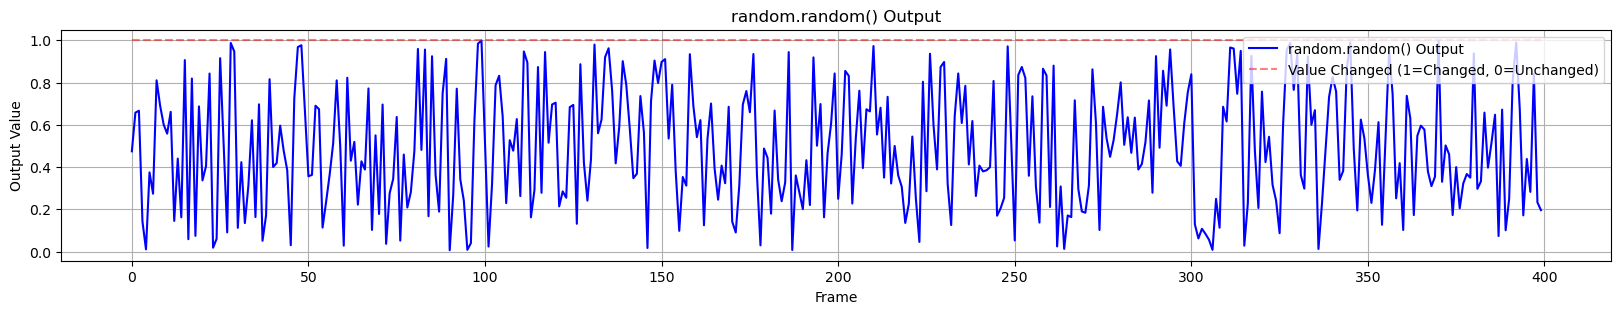

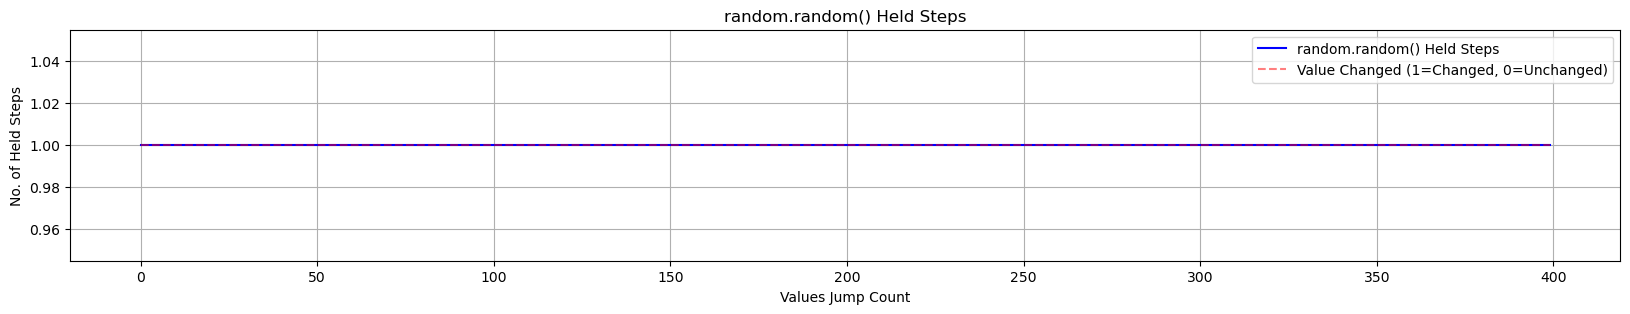

Number of jumps in random.random(): 400 out of 400 steps. Jump frequency: 100.00%


In [176]:
import random
random.seed(12)
values = [random.random() for x in range(400)]
values_changed = [1] * 400
plot_values(values, values_changed, seq_name='random.random()')

# output the changed steps list
held_steps = held_steps_list(values_changed)
# print(held_steps)
held_step_values(held_steps, [1]*len(held_steps), seq_name='random.random()')

# print the number of jumps
print(f"Number of jumps in random.random(): {sum(values_changed)} out of {len(values_changed)} steps. Jump frequency: {sum(values_changed)/len(values_changed)*100:.2f}%")

All held steps are 1. This means that each changed value is held for exactly 1 frame. None of the values are held beyond a single frame.

## Plot `Portable_Rand()`

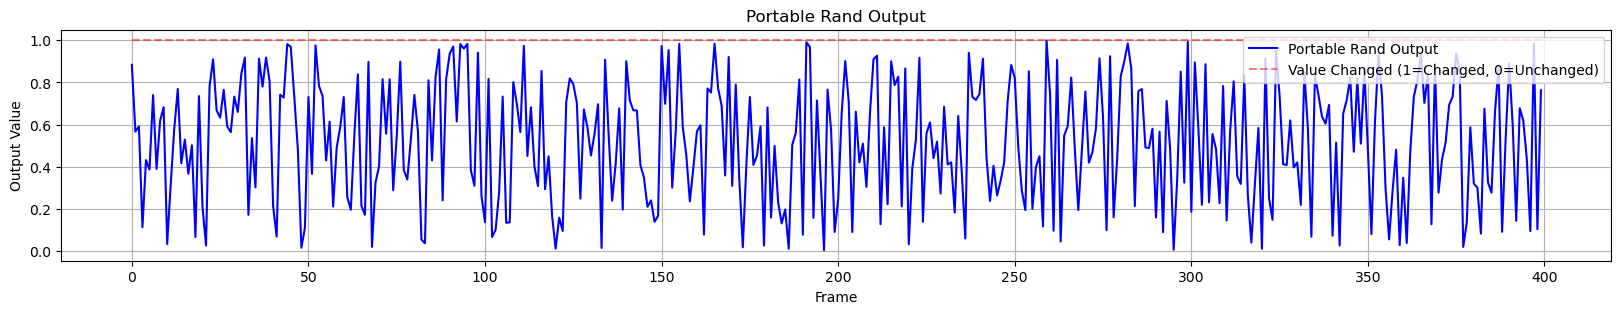

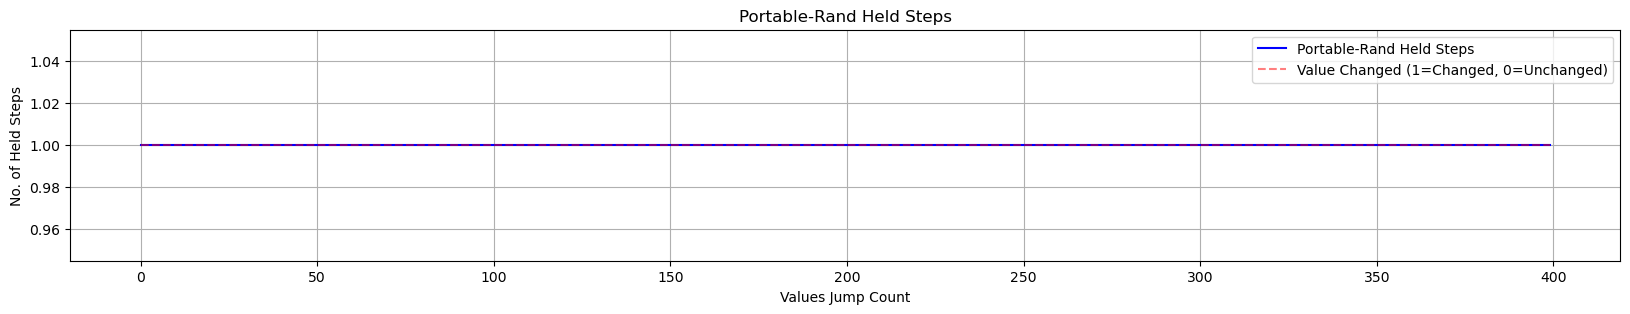

Number of jumps in Portable-Rand: 400 out of 400 steps. Jump frequency: 100.00%


In [177]:
values = [portable_rand(x) for x in range(400)]
values_changed = [1] * 400
plot_values(values, values_changed, seq_name='Portable Rand')

# output the changed steps list
held_steps = held_steps_list(values_changed)
# print(held_steps)
held_step_values(held_steps, [1]*len(held_steps), seq_name='Portable-Rand')

# print the number of jumps
print(f"Number of jumps in Portable-Rand: {sum(values_changed)} out of {len(values_changed)} steps. Jump frequency: {sum(values_changed)/len(values_changed)*100:.2f}%")

All held steps are 1. This means that each changed value is held for exactly 1 frame. None of the values are held beyond a single frame.
This is similar to the behaviour of `random.random()`.

## Plot FPS-R SM

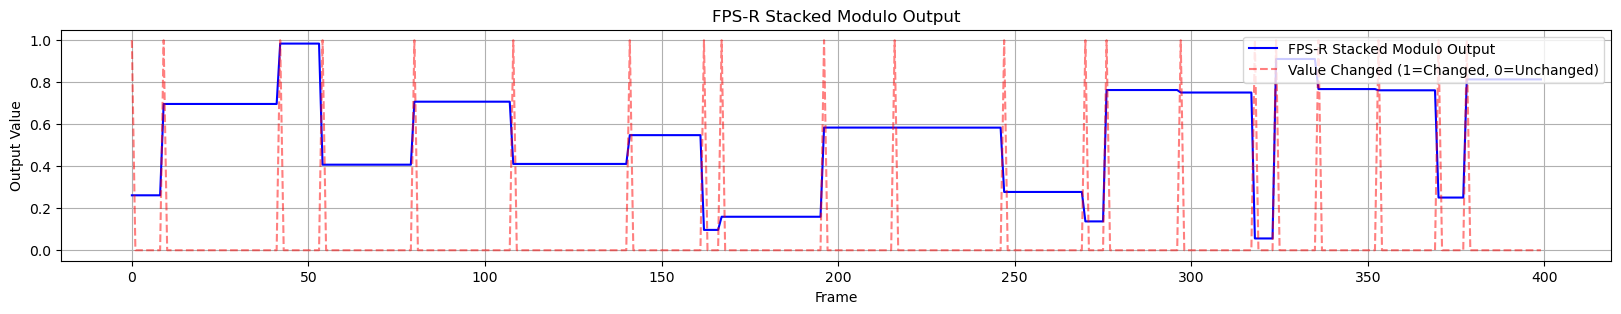

In [178]:
# calling fpsr_sm
values, values_changed = seq_sm(400)
# Plot the distribution of FPS-R SM values
plot_values(values, values_changed, seq_name='FPS-R Stacked Modulo')

FPS-R SM: Number of Steps Held Before the Next Jump

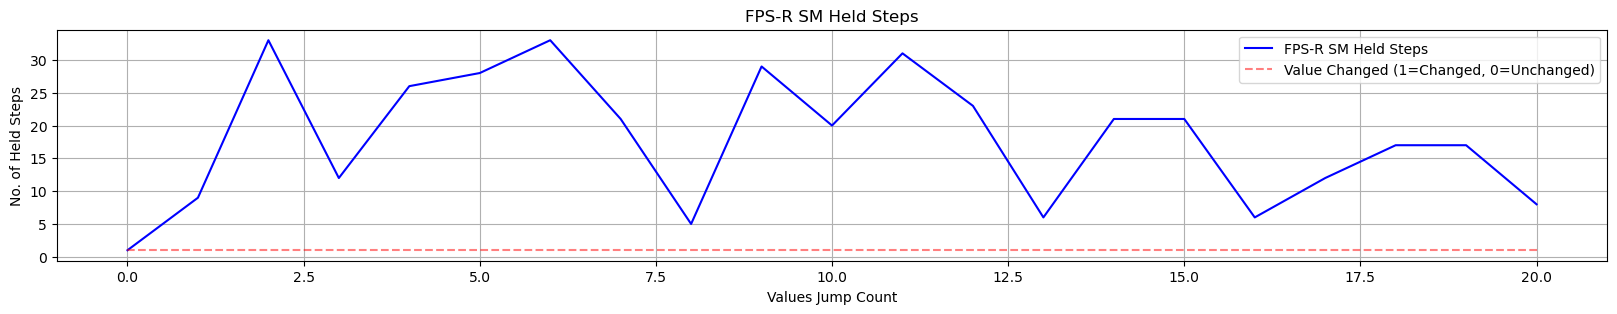

Number of jumps in FPS-R SM: 21 out of 400 steps. Jump frequency: 5.25%


In [179]:
# output the changed steps list
held_steps = held_steps_list(values_changed)
# print(held_steps)
held_step_values(held_steps, [1]*len(held_steps), seq_name='FPS-R SM')
# print the number of jumps
print(f"Number of jumps in FPS-R SM: {sum(values_changed)} out of {len(values_changed)} steps. Jump frequency: {sum(values_changed)/len(values_changed)*100:.2f}%")

## Plot FPS-R SM Distribution Graphs

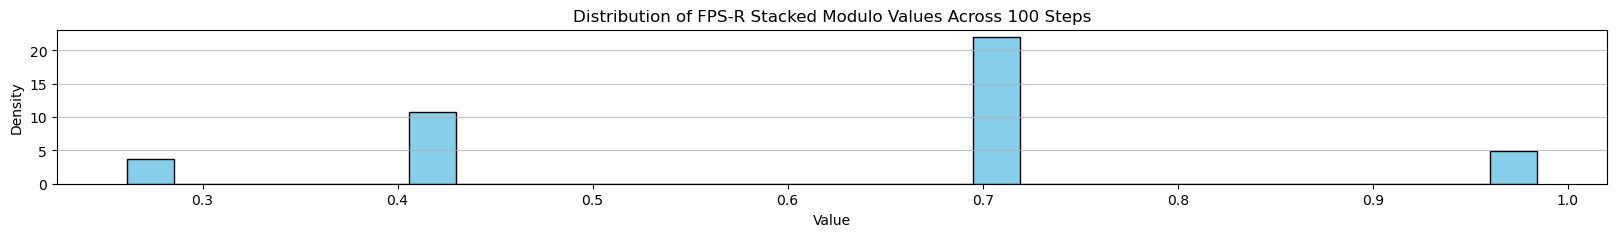

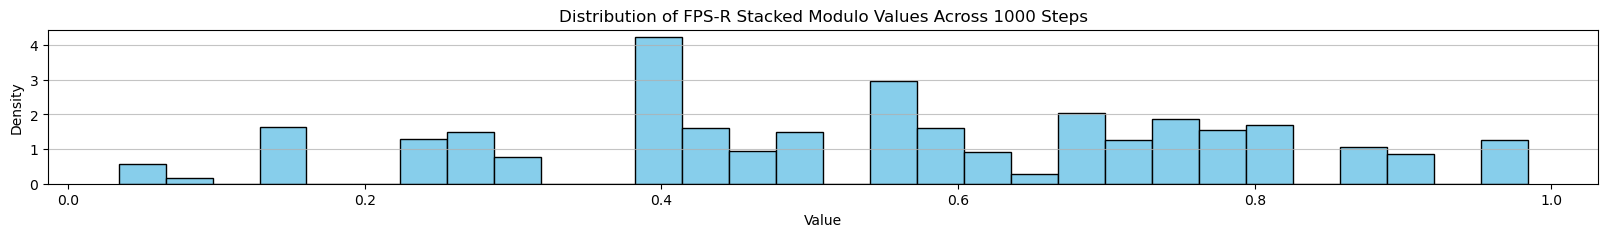

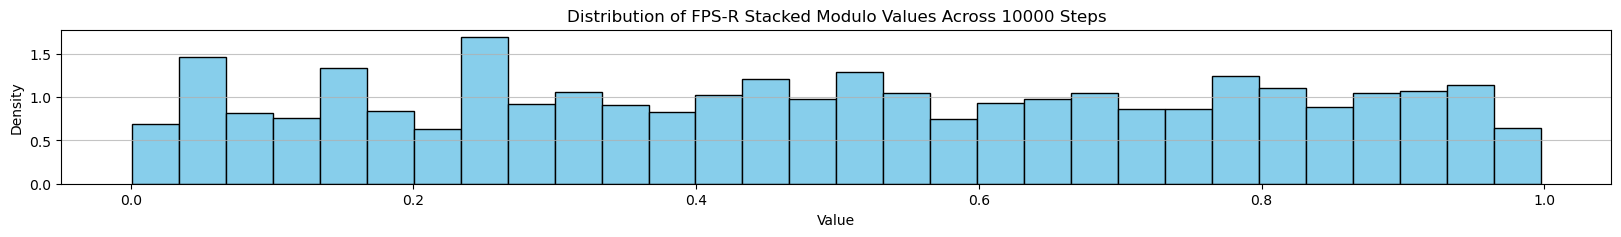

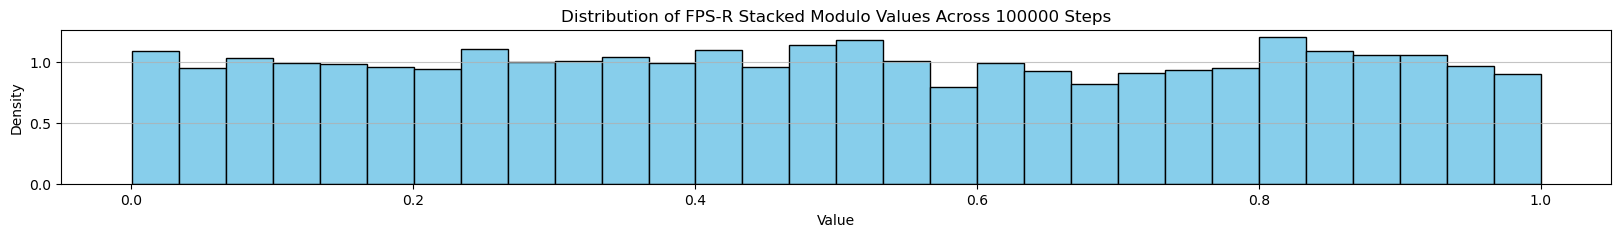

In [180]:
# Distribution Plot for SM
# seq_func points to the supplied function
seq_func = seq_sm
seq_name = 'FPS-R Stacked Modulo'

for frame_count in distri_progressive_steps:
    plot_distribution(seq_func(frame_count), seq_name)
# The distribution of FPS-R QS values show a consistent pattern across different sample sizes.

## Plot FPS-R TM

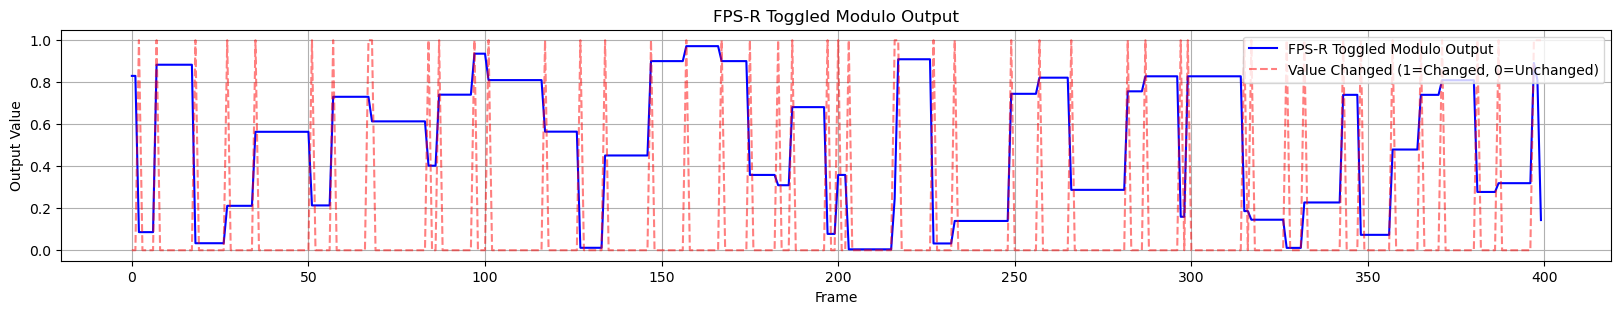

In [181]:
# calling fpsr_tm
values, values_changed = seq_tm(400)
# Plot the distribution of FPS-R TM values
plot_values(values, values_changed, seq_name='FPS-R Toggled Modulo')

FPS-R TM: Number of Steps Held Before the Next Jump

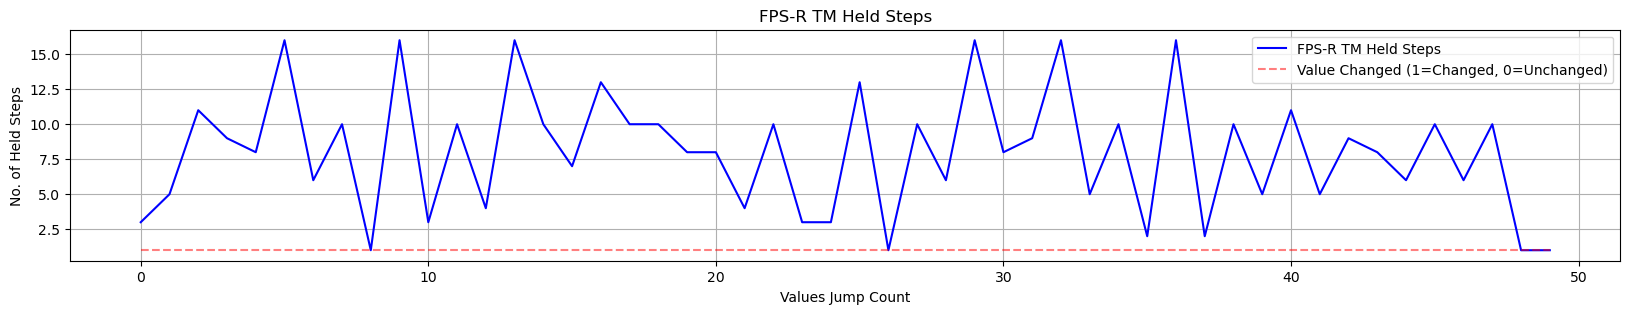

Number of jumps in FPS-R TM: 50 out of 400 steps. Jump frequency: 12.50%


In [182]:
# output the changed steps list
held_steps = held_steps_list(values_changed)
# print(held_steps)
held_step_values(held_steps, [1]*len(held_steps), seq_name='FPS-R TM')
# print the number of jumps
print(f"Number of jumps in FPS-R TM: {sum(values_changed)} out of {len(values_changed)} steps. Jump frequency: {sum(values_changed)/len(values_changed):.2%}")

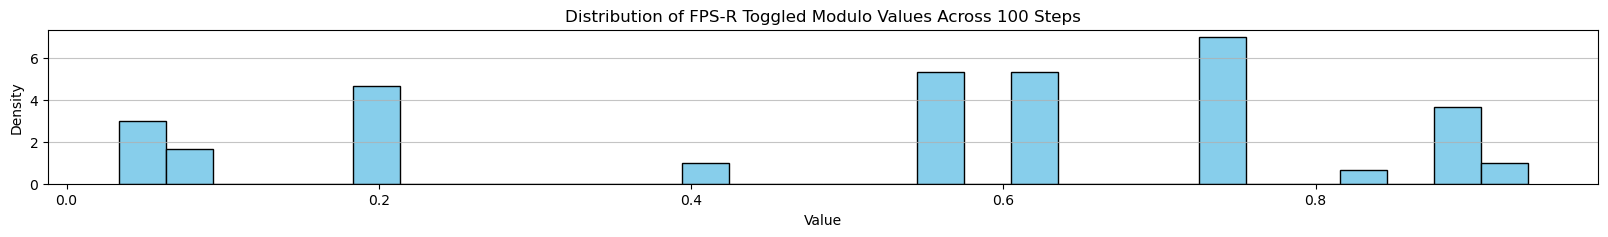

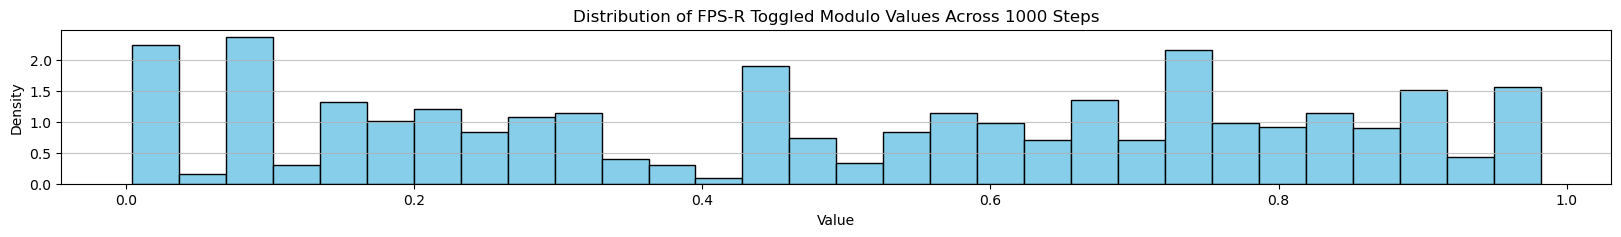

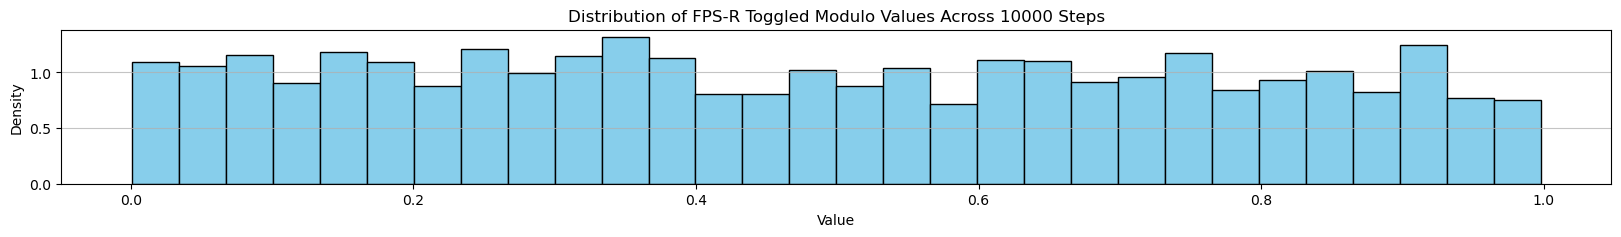

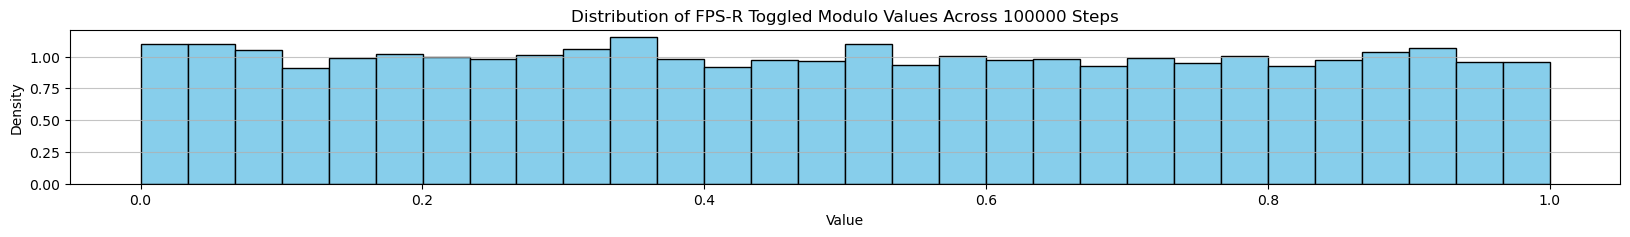

In [183]:
# Distribution Plot for TM
# seq_func points to the supplied function
seq_func = seq_tm
seq_name = 'FPS-R Toggled Modulo'

for frame_count in distri_progressive_steps:
    plot_distribution(seq_func(frame_count), seq_name)
# The distribution of FPS-R QS values show a consistent pattern across different sample sizes.

## Plot FPS-R QS

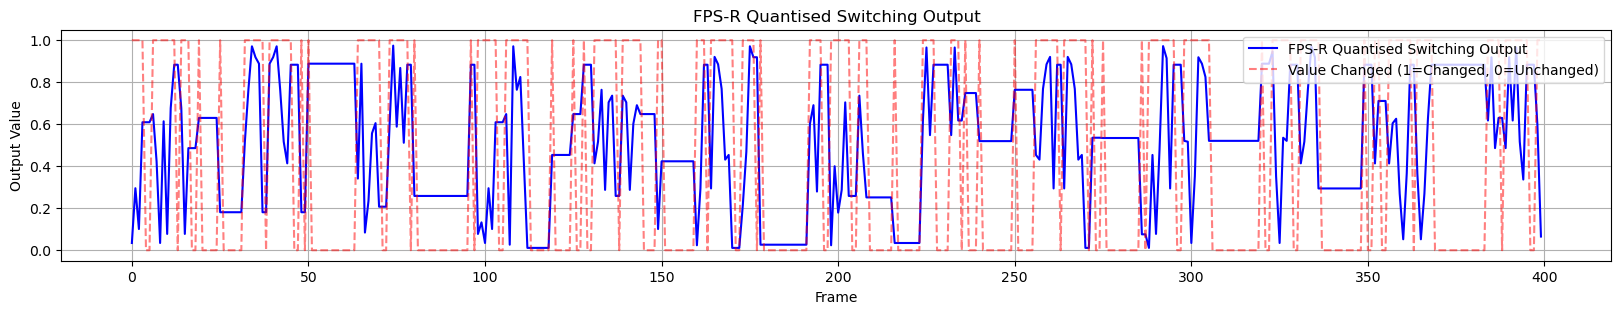

In [184]:
# calling fpsr_qs
values, values_changed = seq_qs(400)
# Plot the distribution of FPS-R QS values
plot_values(values, values_changed, seq_name='FPS-R Quantised Switching')

FPS-R QS: Number of Steps Held Before the Next Jump

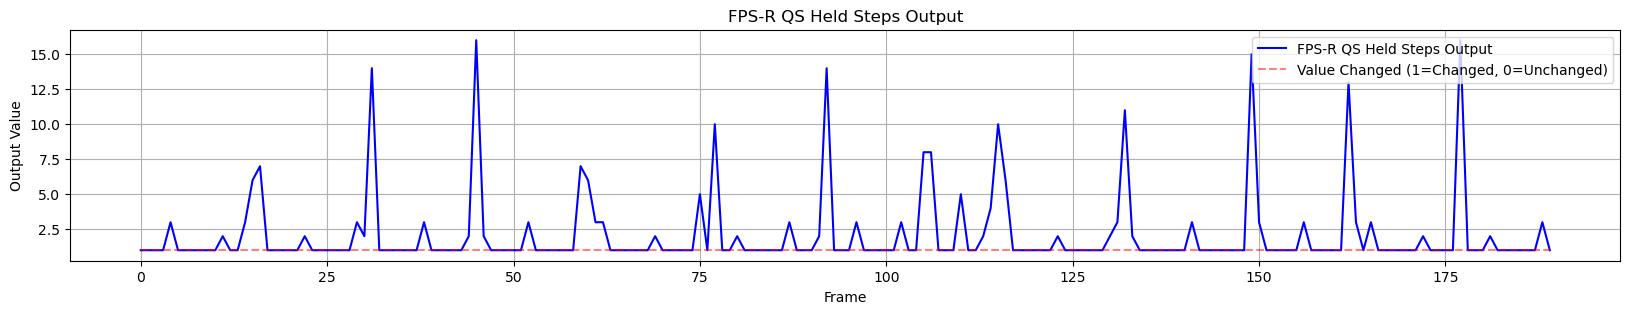

Number of jumps in FPS-R QS: 190 out of 400 steps. Jump frequency: 47.50%


In [185]:
# output the changed steps list
held_steps = held_steps_list(values_changed)
# print(held_steps)
plot_values(held_steps, [1]*len(held_steps), seq_name='FPS-R QS Held Steps')
# print the number of jumps
print(f"Number of jumps in FPS-R QS: {len(held_steps)} out of {len(values_changed)} steps. Jump frequency: {len(held_steps)/len(values_changed):.2%}")

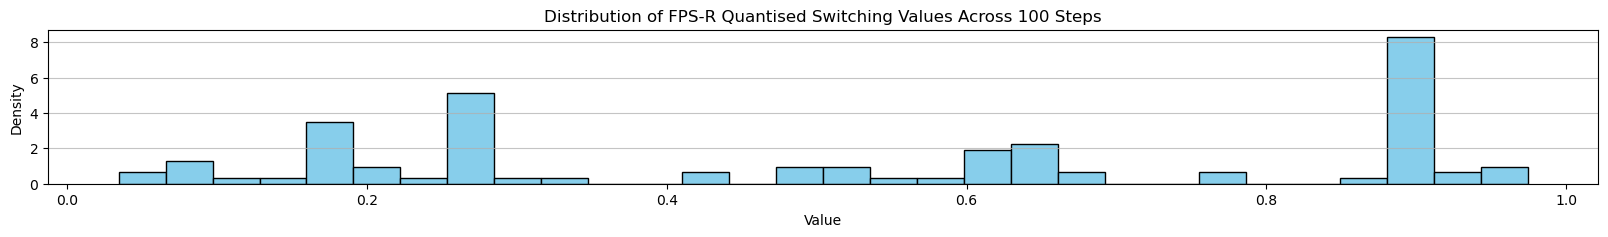

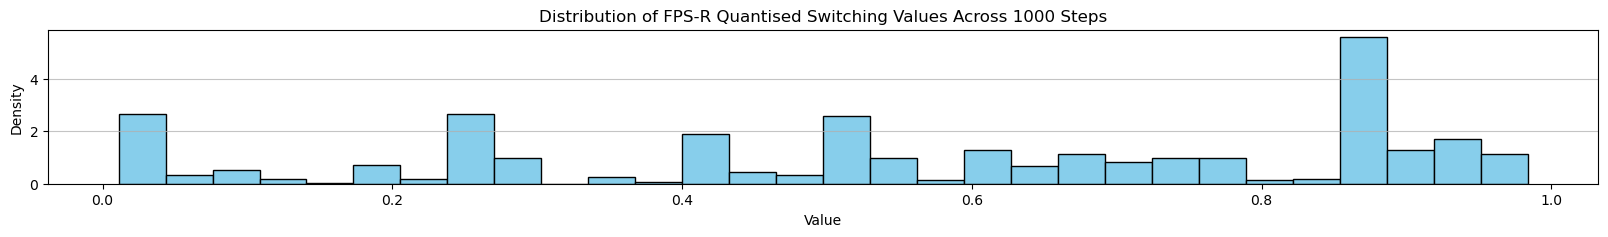

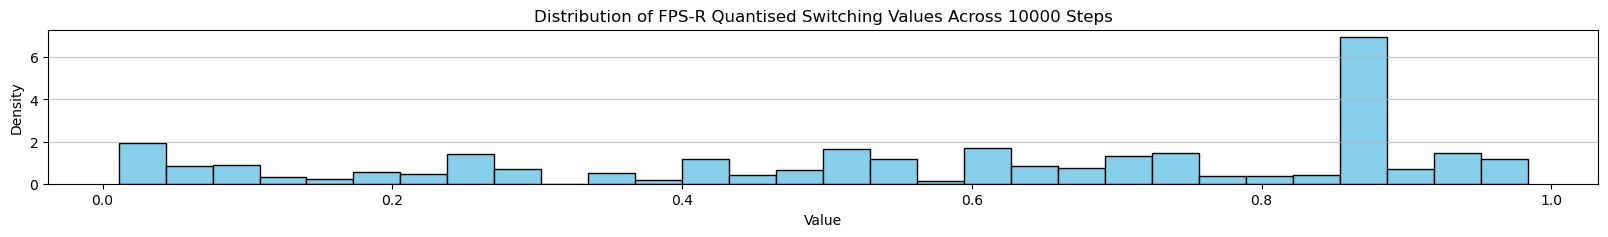

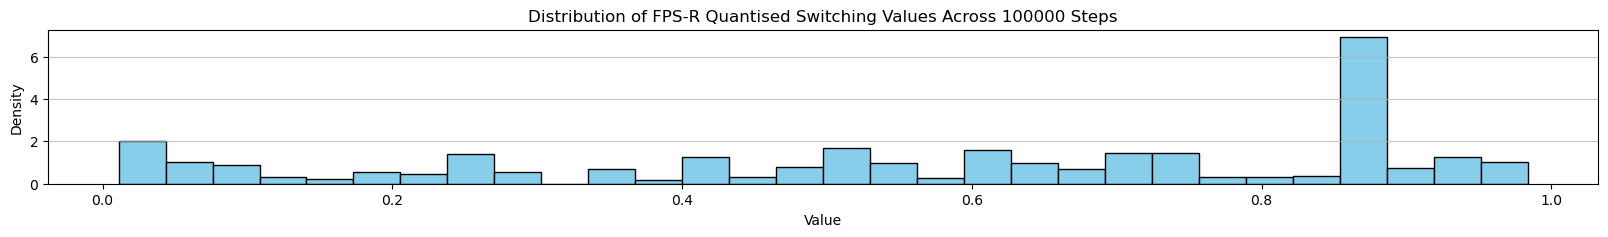

In [186]:
# Distribution Plot for QS
# seq_func points to the supplied function
seq_func = seq_qs
seq_name = 'FPS-R Quantised Switching'

for frame_count in distri_progressive_steps:
    plot_distribution(seq_func(frame_count), seq_name)
# The distribution of FPS-R QS values show a consistent pattern across different sample sizes.

## Plot FPS-R BD

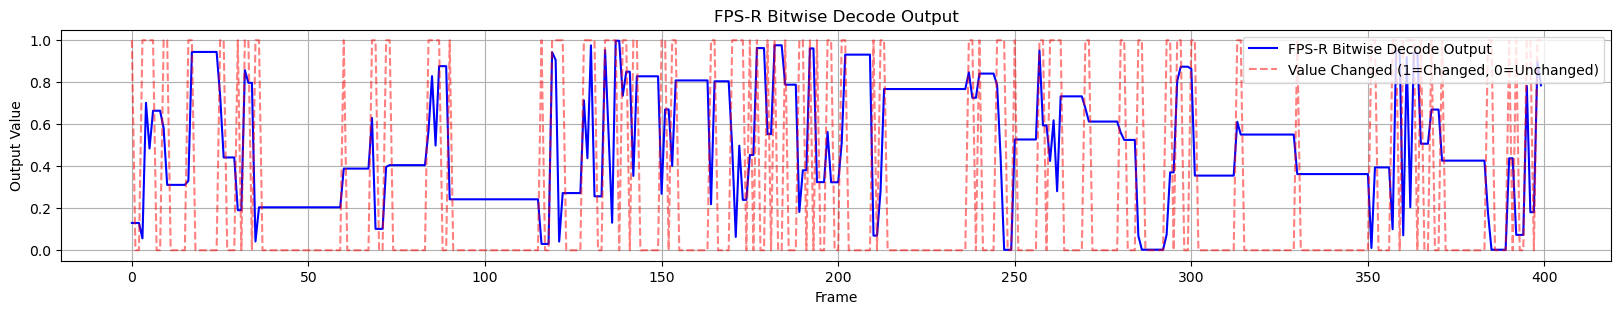

In [187]:
# calling fpsr_bd
values, values_changed = seq_bd(400)
# Plot the distribution of FPS-R BD values
plot_values(values, values_changed, seq_name='FPS-R Bitwise Decode')

FPS-R BD: Number of Steps Held Before the Next Jump

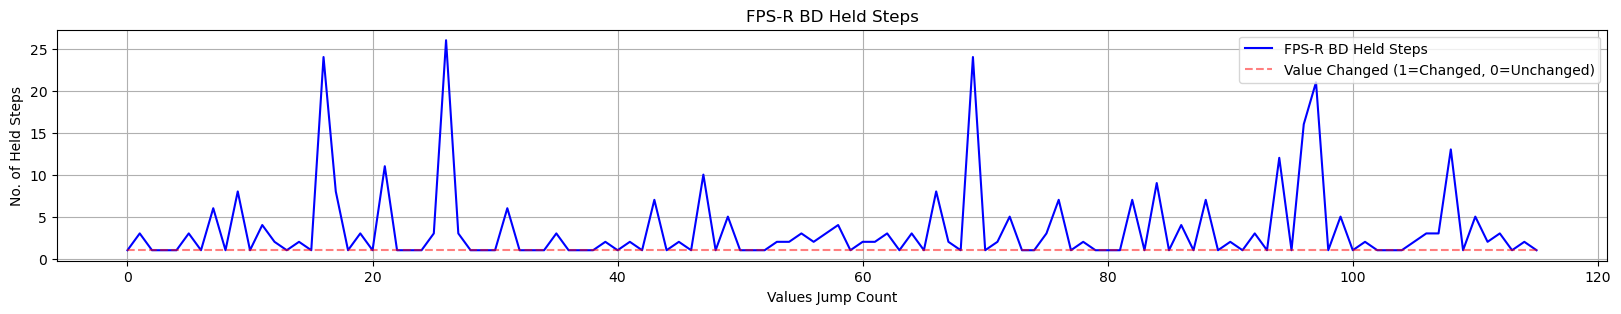

Number of jumps in FPS-R BD: 116 out of 400 steps. Jump frequency: 29.00%


In [188]:
# output the changed steps list
held_steps = held_steps_list(values_changed)
# print(held_steps)
held_step_values(held_steps, [1]*len(held_steps), seq_name='FPS-R BD')
# print the number of jumps
print(f"Number of jumps in FPS-R BD: {len(held_steps)} out of {len(values_changed)} steps. Jump frequency: {len(held_steps)/len(values_changed):.2%}")

## Plot FPS-R BD Distribution Graphs

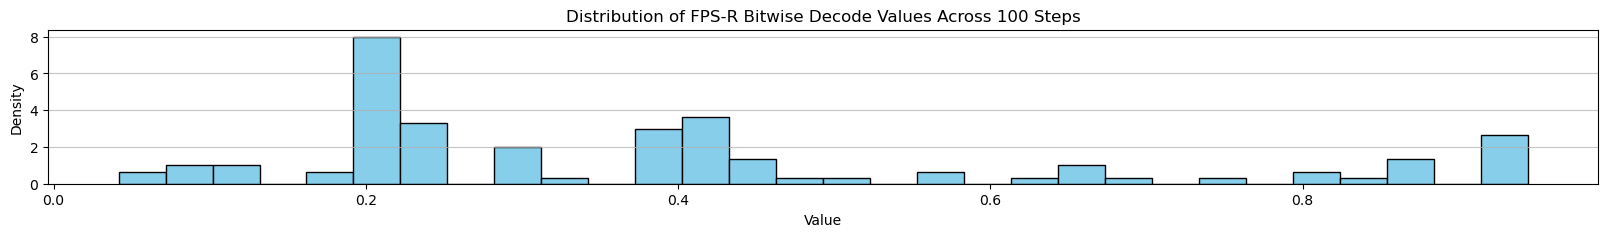

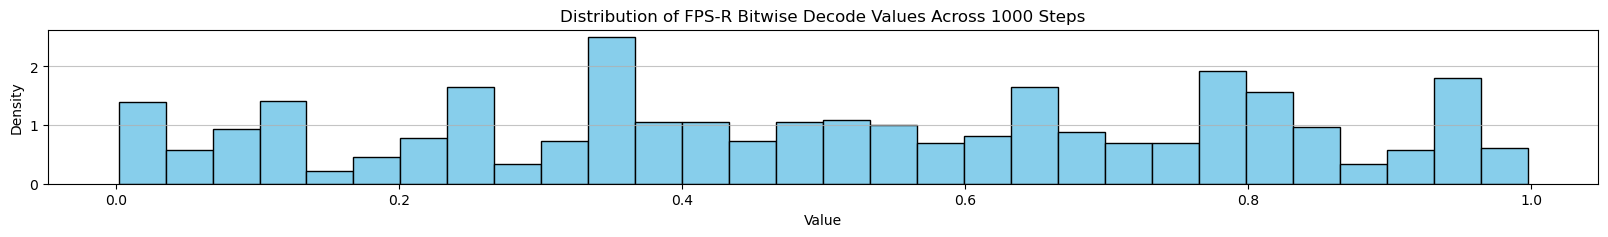

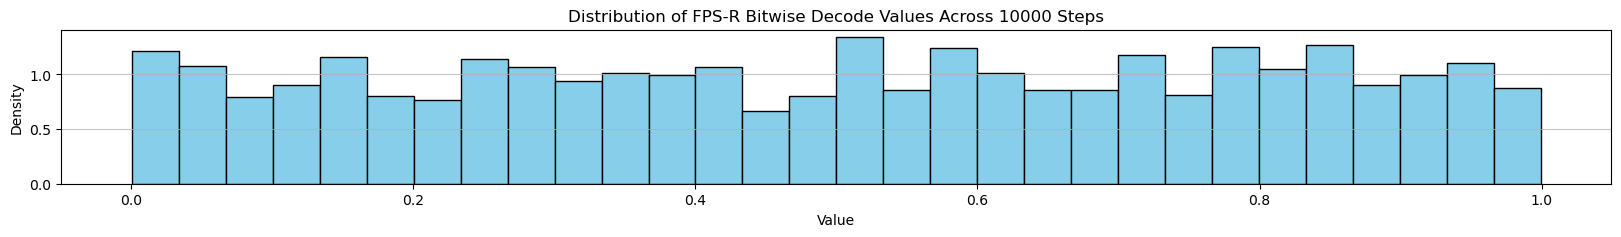

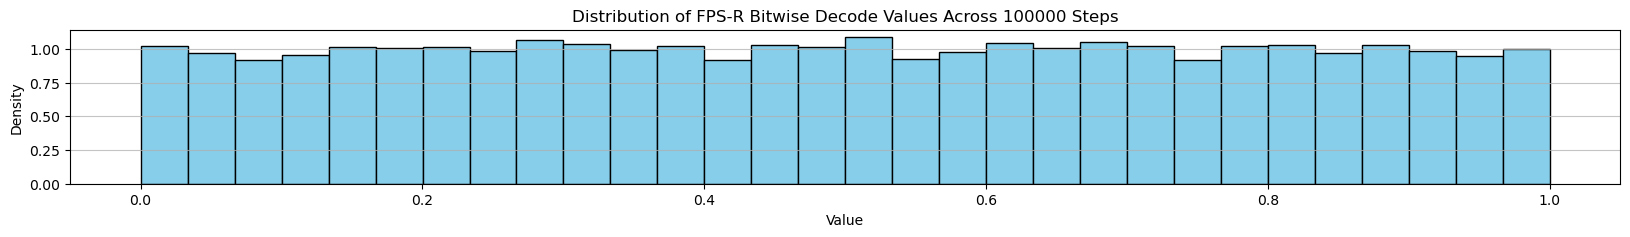

In [189]:
# Distribution Plot for BD
# seq_func points to the supplied function
seq_func = seq_bd
seq_name = 'FPS-R Bitwise Decode'

for frame_count in distri_progressive_steps:
    plot_distribution(seq_func(frame_count), seq_name)
# The distribution of FPS-R BD values show a consistent pattern across different sample sizes.

---

# Create Output Lists

In [190]:
num_entries = 400
values_list = []
values, values_changed = seq_sm(num_entries)
values_list.append(values)
values, values_changed = seq_tm(num_entries)
values_list.append(values)
values, values_changed = seq_qs(num_entries)
values_list.append(values)
values, values_changed = seq_bd(num_entries)
values_list.append(values)

print('Number of Entries:', num_entries)
print(f'SM Values:\n', values_list[0])
print(f'TM Values:\n', values_list[1])
print(f'QS Values:\n', values_list[2])
print(f'BD Values:\n', values_list[3])
# construct a csv-like list from values_list each row is a list of values from each sequence
csv_like_list = []
for i in range(len(values_list[0])):
    row = []
    for j in range(len(values_list)):
        row.append(values_list[j][i])
    csv_like_list.append(row)
# print(len(csv_like_list))
# print(csv_like_list)

Number of Entries: 400
SM Values:
 [0.2615304715693846, 0.2615304715693846, 0.2615304715693846, 0.2615304715693846, 0.2615304715693846, 0.2615304715693846, 0.2615304715693846, 0.2615304715693846, 0.2615304715693846, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.6964858208405288, 0.9839584916326234, 0.9839584916326234, 0.9839584916326234, 0.9839584916326234, 0.9839584916326234, 0.9839584916326234, 0.98